# E104 · Spend before the sell-out: media, bookings and the two clocks of a capacity-limited event

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the **Hotel Booking Demand** data (Antonio, de Almeida & Nunes 2019, *Data in Brief* 22:41-49; CC BY 4.0), 119,390 bookings at a Lisbon city hotel and an Algarve resort. Each arrival date at a hotel is an **event** with a fixed number of rooms, and its kept individual bookings (28,180 in all) over the last 17 weeks before arrival are the real, **no-ad baseline**. Simulated on top: media spend under seven spend plans, a known multiplicative effect with carryover (true $\beta = 0.15$), the extra bookings it brings, and a room limit per hotel, so that every estimate can be graded against the truth |
| **You will learn** | Two clocks for one sale, **lead time** and **calendar date**, and the age-period-cohort line between them · planting a known effect on a real baseline · a Poisson panel with event effects as a fast estimator for many simulated worlds · why **stopping spend at sell-out** doubles the estimated effect, and the **censored likelihood** $P(Y \ge R)$ (with `pm.Censored`'s discrete bound checked) · **reactive pacing** and an instrument that undoes it, **seasonal** spend and booking-date effects · **platform spend** that no observational model identifies · booking curves by event type · the **random-intercept trap** when big events get big budgets, and the **Mundlak** fix, in PyMC · a negative-binomial model with partially pooled curves, a detrended **calendar random walk** and a censored sell-out week; prior and posterior predictive checks of counts and of **sell-out timing** · **incremental bookings under capacity** for the next unit of spend, and **pull-forward** · what carries over to film releases and game launches |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import scipy.sparse as sp
from pymc.blocking import DictToArrayBijection
from scipy import stats
from scipy.optimize import brentq, minimize

from pymc_challenges import data

RANDOM_SEED = 104
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
TYPES = ["City weekday", "City Fri/Sat", "Resort weekday", "Resort Fri/Sat"]
TCOL = dict(zip(TYPES, [BLUE, PURPLE, AQUA, ORANGE]))
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

A ticketing platform hosts thousands of events - concerts, plays, matches, festivals - and each
one has a fixed number of seats. Tickets go on sale weeks or months ahead and arrive along a
**booking curve**: a trickle at first, a surge in the last days. The platform's marketing team
buys paid media for its events in those weeks, and every quarter somebody asks what the money
bought, and where the next euro should go.

The analyst's natural first model lines the events up by **days until the event**, the "t-minus"
clock, because that is where the booking curves look alike. Daily sales of event $e$ at lead time
$l$ are counts with a rate

$$\log \lambda_{el} = a_e + f(l) + \beta\, A_{el}, \qquad a_e \sim N(\mu, \sigma),$$

an event's own level $a_e$, partially pooled across events, a shared booking curve $f(l)$, and a
media effect $\beta$ on adstocked spend $A_{el}$. It is a hierarchical model of the kind PyMC
makes easy, and it is an honest marketing-mix model (Jin, Wang, Sun, Chan & Koehler 2017 give the
Bayesian version with carryover and shape effects). But the spend in such data is not handed out
at random. Budgets go to events the planners expect to be big; pacing tools push money at events
that are behind; spend stops when an event sells out; brand campaigns run on the calendar, not on
any event's clock. Chan & Perry (2017) list exactly this - spend chosen with knowledge of demand -
among the main obstacles to measuring media from observational data, and Blake, Nosko & Tadelis
(2015) showed on eBay's paid search how far such estimates can drift when ads go to buyers who
would have come anyway. Capacity adds a twist: a sold-out event's demand is censored, and spend
that finds it one more buyer buys nothing.

No public ticketing data come with media spend, so we borrow the closest real thing. The Hotel
Booking Demand data (Antonio, de Almeida & Nunes 2019) record every booking at two Portuguese
hotels with its **lead time**. A night at a hotel is an event with a fixed number of rooms, sold
along a booking curve, the object revenue managers forecast with "pickup" methods (Weatherford &
Kimes 2003). Each arrival date at a hotel is one event, and its real bookings are the **organic**
sales it would have had with no ads. On top we simulate media spend with a **known** effect and a
room limit. As in E102 and E103, the baseline is real, the treatment is ours, and every estimate
can be graded.

| part | question | tool |
|---|---|---|
| A | What do real booking curves look like? | events as arrival dates; the two clocks; curves by event type; calendar demand; how persistent an event's surprises are |
| B | How do we plant a known effect? | real bookings as the baseline, Poisson "copies", adstock, a room limit, seven spend plans |
| C | Which spending habits fool the t-minus model? | a Poisson panel with event effects over 27 simulated worlds (seven habits, two controls); censoring, pacing, calendar effects, curves by type, random intercepts |
| D | What does the hierarchical model get wrong? | three PyMC random-intercept models in one decision world; the Mundlak term |
| E | A better model | negative binomial, curves by type, a calendar random walk, a censored sell-out week; prior predictive, diagnostics, predictive checks of counts and of sell-out timing |
| F | What can be repaired, and what cannot | reactive pacing and an instrument; platform spend and randomised variation |
| G | Where should the next unit of spend go? | incremental bookings under capacity, naive against better against truth; pull-forward |
| H | Films and games | what transfers to box office and launch sales |

## A · Real booking curves

The file holds one row per booking, cancelled or not, with the hotel, the arrival date, the lead
time in days and the type of customer.

In [2]:
data.describe("hotel_bookings")
df = data.load("hotel_bookings")
MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October",
          "November", "December"]
df["arrival"] = pd.to_datetime(dict(year=df.arrival_date_year, month=df.arrival_date_month.map(
    {m: i for i, m in enumerate(MONTHS, 1)}), day=df.arrival_date_day_of_month))
print(f"{len(df):,} bookings for arrivals {df.arrival.min():%Y-%m-%d} to {df.arrival.max():%Y-%m-%d}")
print(df.groupby("hotel").agg(bookings=("lead_time", "size"), cancelled=("is_canceled", "mean"),
                              median_lead=("lead_time", "median"),
                              transient=("customer_type", lambda s: (s == "Transient").mean())).round(2).to_string())
print("cancelled share by lead time (days): " + ", ".join(
    f"{k} {v:.0%}" for k, v in df.groupby(pd.cut(df.lead_time, [-1, 7, 30, 60, 120, 240, 800]),
                                          observed=True).is_canceled.mean().items()))

hotel_bookings: One row per booking (including cancelled ones): hotel ('Resort Hotel' or 'City Hotel'), is_canceled, lead_time (days from booking to arrival), arrival_date_year / _month (name) / _week_number / _day_of_month, stays_in_weekend_nights, stays_in_week_nights, adults, children, babies, meal, country, market_segment, distribution_channel, is_repeated_guest, previous_cancellations, previous_bookings_not_canceled, reserved_room_type, assigned_room_type, booking_changes, deposit_type, agent, company (ids or 'NULL'), days_in_waiting_list, customer_type, adr (average daily rate, EUR), required_car_parking_spaces, total_of_special_requests, reservation_status (Check-Out, Canceled, No-Show), reservation_status_date.
  source: Hotel Booking Demand: Antonio, de Almeida & Nunes (2019), 'Hotel booking demand datasets', Data in Brief 22:41-49, doi:10.1016/j.dib.2018.11.126. Licence CC BY 4.0. Booking records of two Portuguese hotels (H1 a resort in the Algarve, H2 a city hotel in Lisbon)

119,390 bookings for arrivals 2015-07-01 to 2017-08-31
              bookings  cancelled  median_lead  transient
hotel                                                    
City Hotel       79330       0.42         74.0       0.75
Resort Hotel     40060       0.28         57.0       0.75
cancelled share by lead time (days): (-1, 7] 10%, (7, 30] 28%, (30, 60] 36%, (60, 120] 42%, (120, 240] 45%, (240, 800] 64%


Two choices define what counts as a sale. First, **cancelled bookings are left out.** Cancellation
is its own process, strongly tied to lead time (10% of last-week bookings are cancelled, 64% of
those made more than 240 days ahead), and would leak into the booking curve and anything that
moves with lead time, spend included. Second, **only "Transient" customers are kept**, three
quarters of each hotel's bookings: individuals booking for themselves, the analogue of a ticket
buyer. The other types are groups, contracts and allotments, blocks of rooms negotiated in one go
(one arrival date receives 93 bookings from a single lead day), which no media campaign would
move.

The window needs one more look. Here are the kept transient bookings per arrival date, month by
month, for the first ten months of the data, and the bookings made in each month against a year
later:

In [3]:
L, W = 119, 17                       # leads 0-118 days: 17 whole weeks
HOTELS = ["City Hotel", "Resort Hotel"]
kept = df[(df.is_canceled == 0) & (df.customer_type == "Transient") & (df.lead_time < L)]
per_date = (kept.groupby(["hotel", "arrival"]).size().unstack(0)
            .reindex(pd.date_range("2015-07-01", "2017-08-31")).fillna(0))
early = per_date.resample("MS").mean().loc["2015-07":"2016-04"]
print("mean kept transient bookings per arrival date, by month of arrival:")
print(early.T.round(1).set_axis([f"{d:%b %y}" for d in early.index], axis=1).to_string())
booked = kept.arrival - pd.to_timedelta(kept.lead_time, "D")      # the other clock: when the booking was made
made = kept.groupby([booked.dt.to_period("M"), kept.hotel]).size().unstack(1)
rows = []
for m in ["2015-09", "2015-10", "2015-11", "2015-12", "2016-01", "2016-02", "2016-03"]:
    p, q = pd.Period(m), pd.Period(m) + 12
    rows.append({"month made": f"{p.strftime('%b %Y')} / {q.strftime('%b %Y')}",
                 **{h.split()[0]: f"{made.loc[p, h]:,.0f} / {made.loc[q, h]:,.0f}" for h in HOTELS}})
print("kept transient bookings MADE in a month (lead 0-118 days), against the same month a year later:")
print(pd.DataFrame(rows).to_string(index=False))

mean kept transient bookings per arrival date, by month of arrival:
              Jul 15  Aug 15  Sep 15  Oct 15  Nov 15  Dec 15  Jan 16  Feb 16  Mar 16  Apr 16
hotel                                                                                       
City Hotel       1.8    14.5    20.3    20.4    12.3    19.0    19.9    35.7    42.6    43.3
Resort Hotel    24.7    24.8    15.6    21.0    20.0    22.0    22.3    31.2    31.9    26.5
kept transient bookings MADE in a month (lead 0-118 days), against the same month a year later:
         month made          City      Resort
Sep 2015 / Sep 2016   782 / 1,475   349 / 622
Oct 2015 / Oct 2016   435 / 1,135   581 / 757
Nov 2015 / Nov 2016     399 / 893   684 / 637
Dec 2015 / Dec 2016   746 / 1,026   538 / 484
Jan 2016 / Jan 2017 1,510 / 2,121 1,015 / 997
Feb 2016 / Feb 2017 1,384 / 1,505 1,105 / 800
Mar 2016 / Mar 2017 1,176 / 1,065   917 / 629


The City Hotel records 1.8 bookings per night in July 2015, 12-20 through January 2016, and then
36-43 from February, while the resort moves smoothly. A Lisbon hotel does not double its
individual demand in a month; this looks like a change in how bookings were recorded. The second
table finds it on the other clock: counting bookings by the month they were **made** (at most 118
days ahead, so both years are counted alike), the City Hotel records 782, 435 and 399 in
September-November 2015 against 1,475, 1,135 and 893 a year later, and the resort is short in
September and October 2015 too. From January 2016 both hotels are of the same order as a year
later, though City's January is still 29% short. A model would read such a gap as a slow start or,
worse, as an effect of whatever spend was running. We therefore start the events at **1 May
2016**, a few days after the first arrival date whose whole sale falls in 2016, and keep #
arrivals to 31 August 2017. The lead window is **0-118 days**, 17 whole weeks, which holds four
fifths of the kept bookings (two thirds of all rows); a platform would only advertise an event in
its last few months.

In [4]:
ARR0, ARR1 = "2016-05-01", "2017-08-31"       # every booking date on or after 4 January 2016
DATES = pd.date_range(ARR0, ARR1)
ND = len(DATES)
HOTELS = ["City Hotel", "Resort Hotel"]
E = 2 * ND
k_ = kept[(kept.arrival >= ARR0) & (kept.arrival <= ARR1)]
Y0 = np.zeros((E, L), np.int64)                           # column j = lead L-1-j: columns run in time order
np.add.at(Y0, (pd.Index(HOTELS).get_indexer(k_.hotel) * ND + DATES.get_indexer(k_.arrival),
               (L - 1) - k_.lead_time.to_numpy()), 1)
HOTEL = np.repeat([0, 1], ND)
ADATE = pd.DatetimeIndex(np.tile(DATES, 2))
WKEND = ADATE.dayofweek.isin([4, 5]).astype(int)          # Friday and Saturday arrivals
ETYPE = 2 * HOTEL + WKEND
LEAD = (L - 1) - np.arange(L)
BDATE = np.tile(np.arange(ND), 2)[:, None] + np.arange(L)[None, :]   # booking date, 0 = 118 days before ARR0
NB = BDATE.max() + 1
BDATE_TS = pd.Timestamp(ARR0) - pd.Timedelta(days=L - 1) + pd.to_timedelta(np.arange(NB), "D")
TOT0 = Y0.sum(1)
CAP = np.zeros(E)
for h in (0, 1):
    CAP[HOTEL == h] = np.ceil(np.quantile(TOT0[HOTEL == h], 0.9))   # rooms: the 90th percentile of real events
print(f"{E:,} events ({ND} arrival dates x 2 hotels), {Y0.size:,} event-days, {Y0.sum():,} bookings; "
      f"mean {Y0.mean():.2f} per event-day (variance {Y0.var():.2f}), largest {Y0.max()}")
print(pd.DataFrame({"events": np.bincount(ETYPE), "mean": [TOT0[ETYPE == t].mean() for t in range(4)],
                    "sd": [TOT0[ETYPE == t].std() for t in range(4)],
                    "90th pct": [np.quantile(TOT0[ETYPE == t], 0.9) for t in range(4)],
                    "share at lead 0": [Y0[ETYPE == t, -1].sum() / Y0[ETYPE == t].sum() for t in range(4)]},
                   index=TYPES).round(2).to_string())
print(f"capacity (rooms): City {CAP[0]:.0f}, Resort {CAP[-1]:.0f}")

976 events (488 arrival dates x 2 hotels), 116,144 event-days, 28,180 bookings; mean 0.24 per event-day (variance 0.54), largest 29
                events   mean     sd  90th pct  share at lead 0
City weekday       350  39.84  14.87      59.0             0.08
City Fri/Sat       138  35.75  14.94      55.3             0.07
Resort weekday     350  18.56   8.65      30.1             0.17
Resort Fri/Sat     138  20.33  11.28      36.3             0.12
capacity (rooms): City 58, Resort 32


The panel has 976 events and 116,144 event-days, with 28,180 bookings: a quarter of a booking per
event-day on average, a variance more than twice the mean, at most 29 in one cell. We give each
event a **type**, hotel by whether it is a Friday or Saturday arrival, because the curves differ:
at the resort, 17% of weekday arrivals' bookings come on the day itself, against 12% for weekend
arrivals and 7-8% at the city hotel. A City event sells about 36-40 rooms to individuals, a Resort
event 19-20, with a standard deviation of roughly 40-55% of that.

Each hotel gets a **capacity** of the 90th percentile of its real event totals, 58 rooms for City
and 32 for Resort. The real hotels are bigger; the limit stands in for the share of rooms left to
individual buyers once groups and contracts are placed, and it is set so that capacity binds often
once media adds bookings, as it does for popular events.

### A1 · Two clocks

Every booking sits on two clocks at once. Its **lead time** $l$ places it on the event's booking
curve. Its **booking date** $d = t_e - l$, where $t_e$ is the arrival date, places it on the
calendar, where the market's mood, holidays, competitors and most media live. In demography this
is the age-period-cohort problem: the event is the cohort, the lead time the age, the booking date
the period, and since $t_e = d + l$, a linear trend in any one of them can be written as trends in
the other two. We measure the calendar part as observed over expected bookings per booking date,
"expected" spreading each event's total over its type's curve. And we ask whether an event that
starts slowly stays slow, by correlating its log bookings in three lead windows, relative to
events of the same hotel, month, year and weekday type.

In [5]:
def type_curves():
    """Log share of organic bookings by lead, per event type (7-day running mean), centred."""
    f = np.zeros((4, L))
    for t in range(4):
        s = Y0[ETYPE == t].sum(0).astype(float)
        sm = np.convolve(np.pad(s, 3, mode="edge"), np.ones(7) / 7, mode="valid")
        f[t] = np.log(sm / sm.mean())
    return f - f.mean(1, keepdims=True)


def calendar_index():
    """Market demand by booking date: log(observed / expected) bookings made that day, where 'expected'
    spreads each event's total over its type's booking curve (7-day running sums, +5 bookings prior)."""
    share = np.stack([Y0[ETYPE == t].sum(0) / Y0[ETYPE == t].sum() for t in range(4)])
    expct = TOT0[:, None] * share[ETYPE]
    obs = np.bincount(BDATE.ravel(), weights=Y0.ravel().astype(float), minlength=NB)
    ex = np.bincount(BDATE.ravel(), weights=expct.ravel(), minlength=NB)
    num = np.convolve(np.pad(obs, 3, mode="edge"), np.ones(7), mode="valid")
    den = np.convolve(np.pad(ex, 3, mode="edge"), np.ones(7), mode="valid")
    s = np.log((num + 5.0) / (den + 5.0))
    return s - np.average(s, weights=ex + 1e-9)


F_TYPE, S_CAL = type_curves(), calendar_index()
key = pd.Series(HOTEL * 10_000 + ADATE.year * 100 + ADATE.month * 2 + WKEND)
dev = {}
for nm, sel in [("early (61-118 d)", LEAD >= 61), ("middle (31-60 d)", (LEAD >= 31) & (LEAD <= 60)),
                ("late (0-30 d)", LEAD <= 30)]:
    x = np.log1p(Y0[:, sel].sum(1))
    dev[nm] = x - pd.Series(x).groupby(key).transform("mean").to_numpy()
print("correlation of an event's demand deviations between lead windows:")
print(pd.DataFrame(dev).corr().round(2).to_string())
print(f"calendar index: sd {S_CAL.std():.2f}, range {S_CAL.min():.2f} to {S_CAL.max():.2f}")

correlation of an event's demand deviations between lead windows:
                  early (61-118 d)  middle (31-60 d)  late (0-30 d)
early (61-118 d)              1.00              0.23           0.06
middle (31-60 d)              0.23              1.00           0.22
late (0-30 d)                 0.06              0.22           1.00
calendar index: sd 0.24, range -0.60 to 1.04


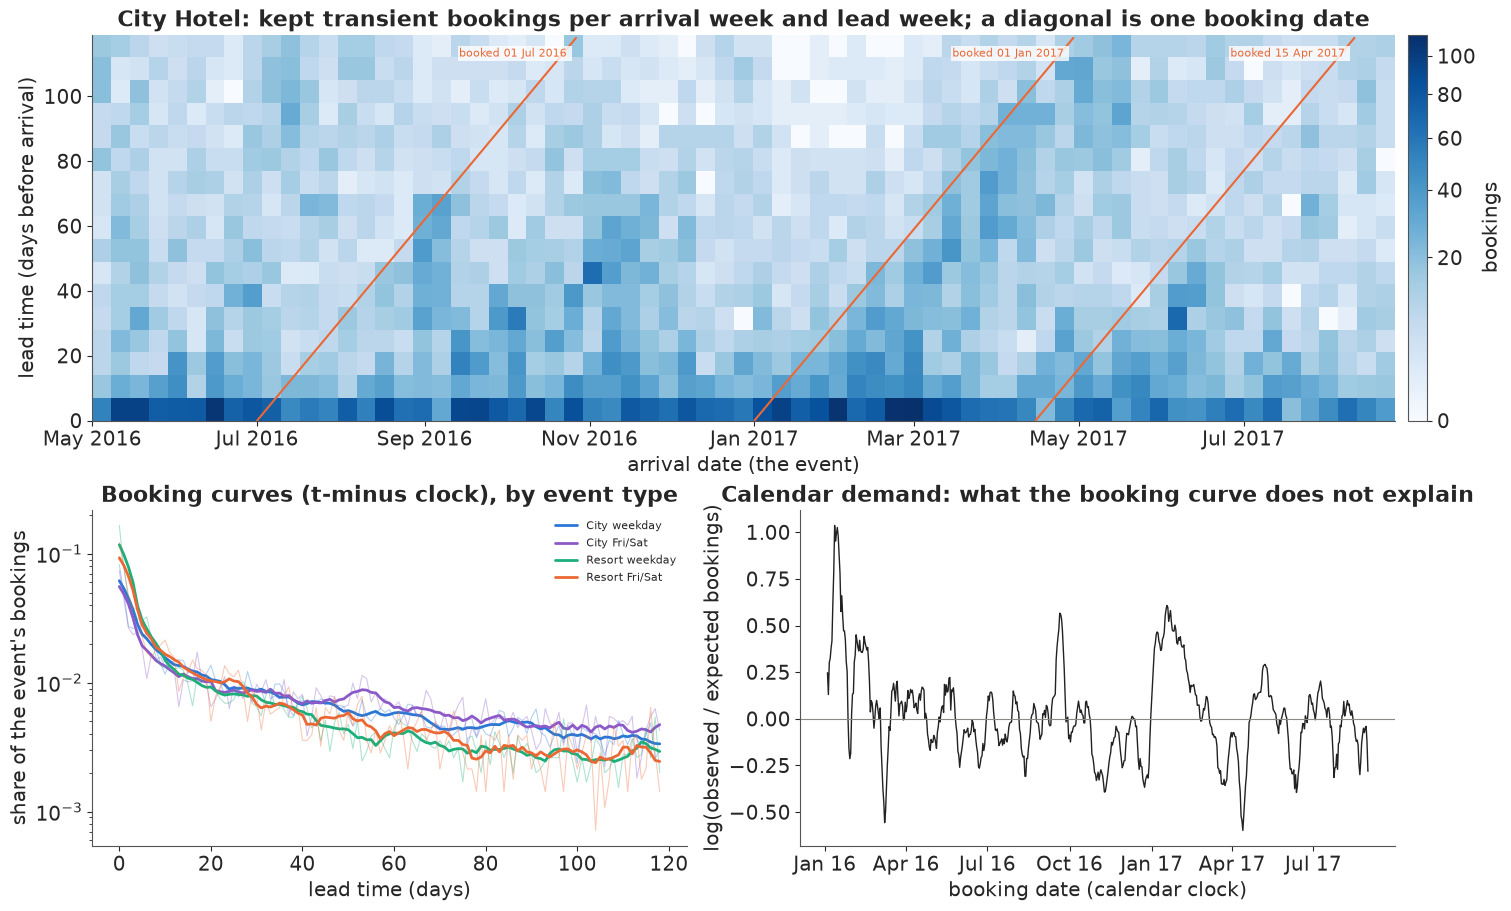

In [6]:
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
ax = fig.add_subplot(gs[0, :])
nwk = ND // 7
Mw = Y0[:nwk * 7][:, ::-1].reshape(nwk, 7, L).sum(1).reshape(nwk, W, 7).sum(2)   # City: arrival x lead weeks
x0, x1 = mdates.date2num(DATES[0]), mdates.date2num(DATES[nwk * 7 - 1])
im = ax.imshow(Mw.T, origin="lower", aspect="auto", extent=[x0, x1, 0, L], cmap="Blues", interpolation="nearest",
               norm=mcolors.PowerNorm(0.5))
for b in ["2016-07-01", "2017-01-01", "2017-04-15"]:
    bx = mdates.date2num(pd.Timestamp(b))
    ax.plot([bx, bx + L - 1], [0, L - 1], color=ORANGE, lw=1.5)
    ax.text(bx + L - 3, L - 4, f"booked {pd.Timestamp(b):%d %b %Y} ", color=ORANGE, fontsize=8, ha="right", va="top",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set(xlim=(x0, x1), ylim=(0, L), xlabel="arrival date (the event)", ylabel="lead time (days before arrival)",
       title="City Hotel: kept transient bookings per arrival week and lead week; a diagonal is one booking date")
fig.colorbar(im, ax=ax, label="bookings", pad=0.01)
ax = fig.add_subplot(gs[1, 0])
for t, nm in enumerate(TYPES):
    s = Y0[ETYPE == t].sum(0)[::-1] / Y0[ETYPE == t].sum()
    ax.plot(np.arange(L), s, color=TCOL[nm], lw=0.8, alpha=0.35)
    ax.plot(np.arange(L), np.convolve(np.pad(s, 3, mode="edge"), np.ones(7) / 7, mode="valid"), color=TCOL[nm],
            lw=2, label=nm)
ax.set(yscale="log", xlabel="lead time (days)", ylabel="share of the event's bookings",
       title="Booking curves (t-minus clock), by event type")
ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 1])
ax.plot(BDATE_TS, S_CAL, color=INK, lw=1)
ax.axhline(0, color=MUTED, lw=0.8)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set(xlabel="booking date (calendar clock)", ylabel="log(observed / expected bookings)",
       title="Calendar demand: what the booking curve does not explain");

The top panel is a Lexis diagram of the City Hotel: columns are arrival weeks, rows lead weeks,
and the dark band along the bottom is the last-minute surge every event shares. Lining events up
by t-minus reads it row by row; the calendar reads it along the orange diagonals, each the
bookings made on one date. Busy arrival periods show as darker vertical stripes, calendar surges
as diagonal streaks, such as the one running up from the January 2017 bookings.

The booking curves (bottom left) are steeper for the resort's weekday arrivals than for anything
else, so one pooled curve would be wrong for every type in a different way. The calendar index
(bottom right) has a standard deviation of 0.24 on the log scale: real swings in when people book,
with peaks in January of both years and in October 2016, and dips to about -0.6 in March 2016 and
April 2017.

The correlations matter for pacing. An event that sells better than its peers early sells only
slightly better in the middle window (0.23) and hardly at all late (0.06): real demand surprises
here are **short-lived**, and a simulation with persistent "buzz" would exaggerate what reacting
to a slow start can do to an estimate.

## B · Planting a known media effect

Write $Y^0_{el}$ for the real organic bookings of event $e$ at lead $l$. The platform spends
$s_{el}$ (in thousands of euros a day) on the event, and spend carries over with geometric
**adstock**,

$$A_{el} = s_{el} + \alpha\, A_{e,l+1}, \qquad \alpha = 0.5,$$

accumulated over the days the event is on sale (lead $l+1$ is the day before lead $l$). We want
the media effect to be multiplicative, $E[Y_{el}] = \lambda_{el}\, e^{\beta A_{el}}$ with $\beta =
0.15$, without having to know the real rate $\lambda_{el}$. A simple construction does it: every
real booking brings Poisson "copies",

$$Y_{el} = Y^0_{el} + \text{Poisson}\big(Y^0_{el}\,(e^{\beta A_{el}} - 1)\big), \qquad
E[Y_{el} \mid Y^0_{el}] = Y^0_{el}\, e^{\beta A_{el}}.$$

Whatever the real rate behind $Y^0_{el}$ was, the expected sale is that rate times $e^{\beta
A_{el}}$, and every real feature of the baseline - its overdispersion, its calendar shocks, its
booking curves - carries through. A day with no organic booking gets no media booking either; that
is the price of not smoothing the baseline. A spend of 1 a day gives an adstock of about 2, so a
typical day's sales rise by $e^{0.3} - 1 \approx 35\%$.

Capacity enters as a running count. Event $e$ has $C_e$ rooms; on the day its cumulative sales
reach $C_e$ it **sells out**, the day records only the remaining rooms, and nothing sells
afterwards. Part C builds its worlds from these spend plans:

| plan | how the daily spend is set |
|---|---|
| random | Gamma with mean 1, independent of everything: the sanity check |
| seasonal | random times $e^{s(d)}$, where $s(d)$ is the calendar index of part A, built from these same bookings: more money in busy weeks |
| curve-timed | random times a weight from the event type's own booking curve, $e^{0.4 f_{\text{type}}(l)}$ |
| platform | one brand series by booking date, the same for every event on sale, carried over on the calendar; optionally scaled by $e^{s(d)}$ to follow the season |
| reactive | $e^{2 g}$ times a random factor (sd 0.3 on the log scale), $g$ the event's shortfall against a pacing target built from a planner's forecast |
| size | a budget proportional to the event's real organic total (times noise), constant over the sale, optionally with weekly **flights** (log sd 0.3) |
| budget | randomised budgets across events (log sd 0.5) with weekly flights: a budget experiment |

and two switches: whether rooms are limited, and whether spend **stops** at sell-out, as it does
in practice. Two plans know more than a planner could: the size budgets use each event's realised
organic total, and the seasonal index is computed from the very bookings it is graded against, so
it follows their noise as well as the season. Both are the strongest form of their habit. Spend
plans and outcome noise have separate seeds, so a world can be replayed with another budget and
the same random numbers.

In [7]:
BETA, ALPHA = 0.15, 0.5             # true log-lift per unit of adstock (EUR 1k a day), daily carryover
KEY_FC = HOTEL * 100 + ADATE.month.to_numpy() * 2 + WKEND
g_fc = pd.Series(TOT0).groupby(KEY_FC)                              # hotel x month x weekday type, 8-46 events
FC = ((g_fc.transform("sum") - TOT0) / (g_fc.transform("size") - 1)).to_numpy()   # forecast: the OTHER events' mean
SHARE = np.stack([Y0[ETYPE == t].sum(0) / Y0[ETYPE == t].sum() for t in range(4)])[ETYPE]
PLAN_CUM = FC[:, None] * np.cumsum(SHARE, 1) * np.exp(BETA * 2.0)   # the pacing target, media included


def adstock(x, alpha=ALPHA):
    """Geometric carryover along the second axis (days on sale)."""
    out, a = np.empty_like(x), np.zeros(x.shape[0])
    for j in range(x.shape[1]):
        a = x[:, j] + alpha * a
        out[:, j] = a
    return out


def spend_plan(policy, seed, flight_sd=0.0):
    """Planned daily spend (EUR 1k) per event and day on sale, before any sell-out, under one policy."""
    rs = np.random.default_rng(seed)
    base = rs.gamma(2.0, 0.5, (E, L))                                  # mean 1 a day, independent of everything
    out = {"budget": np.ones(E), "A_cal": None}
    if policy == "random":
        plan = base
    elif policy == "seasonal":                                         # more money when the market is busy
        plan = base * np.exp(S_CAL[BDATE])
    elif policy == "curve":                                            # follows each type's own booking curve
        w = np.exp(0.4 * F_TYPE)
        plan = base * (w / w.mean(1, keepdims=True))[ETYPE]
    elif policy in ("platform", "platform, seasonal"):                 # one brand series, the same for all events
        series = rs.gamma(2.0, 0.5, NB)
        if policy == "platform, seasonal":                             # ... that also follows the market
            series *= np.exp(S_CAL) / np.exp(S_CAL).mean()
        plan = series[BDATE]
        out["A_cal"] = adstock(series[None, :])[0][BDATE]              # carried over on the calendar
    elif policy in ("size", "budget"):
        if policy == "size":                                           # big events get big budgets
            B = (TOT0 / TOT0.mean()).clip(0.05) * rs.lognormal(-0.02, 0.2, E)
        else:                                                          # randomised budgets (an experiment)
            B = rs.lognormal(-0.125, 0.5, E)
        fl = rs.lognormal(-flight_sd ** 2 / 2, flight_sd, (E, W)) if flight_sd > 0 else np.ones((E, W))
        plan = B[:, None] * np.repeat(fl, 7, axis=1) * rs.lognormal(-0.02, 0.2, (E, L))
        out["budget"] = B
    elif policy == "reactive":                                         # the random factor; pacing comes later
        plan = rs.lognormal(-0.045, 0.3, (E, L))
    out["plan"] = plan
    return out


def simulate(sp_, seed, capped=False, stop=False, reactive=False, phi=0.0, scale=None, beta=BETA):
    """One world: real organic bookings Y0 plus Poisson(Y0 (e^{beta A} - 1)) media bookings, a room limit,
    and spend that may stop at sell-out or chase the pacing target. Outcome noise comes from its own seed
    (inverse-CDF draws), so two budgets run with one seed share their random numbers."""
    ro = np.random.default_rng(seed)
    U = ro.random((E, L))
    plan = sp_["plan"] if scale is None else sp_["plan"] * scale[:, None]
    cap = CAP if capped else np.full(E, np.inf)
    Yc = Y0.astype(float).copy()                                       # organic bookings still to come
    y, A, spend, Aplan = (np.zeros((E, L)) for _ in range(4))
    cens, live = np.zeros((E, L), bool), np.ones((E, L), bool)
    rem, cum, sold, a, ap = cap.copy(), np.zeros(E), np.zeros(E, bool), np.zeros(E), np.zeros(E)
    pulled = np.zeros(E)
    for j in range(L):
        if reactive:                                                   # behind the pacing target: spend more
            prev = PLAN_CUM[:, j - 1] if j else np.ones(E)
            gap = np.clip((prev - cum) / np.maximum(prev, 1.0), -0.5, 0.5) if j else np.zeros(E)
            sp_d = np.exp(2.0 * gap) * plan[:, j]
            ap = np.exp(2.0 * gap) + ALPHA * ap                        # adstock of the planned part
        else:
            sp_d = plan[:, j].copy()
        if stop:
            sp_d = np.where(sold, 0.0, sp_d)
        a = sp_d + ALPHA * a if sp_["A_cal"] is None else sp_["A_cal"][:, j]
        extra = np.maximum(stats.poisson.ppf(U[:, j], Yc[:, j] * np.expm1(beta * a)), 0.0)
        if phi > 0:                       # a share phi of media buyers would have booked this event later anyway
            take = ro.binomial(extra.astype(np.int64), phi)
            for e in np.flatnonzero(take):
                fut = Yc[e, j + 1:].astype(np.int64)
                n_ = min(take[e], fut.sum())
                if n_ > 0:
                    Yc[e, j + 1:] -= ro.multivariate_hypergeometric(fut, n_)
                    pulled[e] += n_
        yd = Yc[:, j] + extra
        live[:, j] = ~sold
        hit = ~sold & (yd >= rem)
        yd = np.where(sold, 0.0, np.minimum(yd, rem))
        cens[:, j] = hit
        rem -= yd
        cum += yd
        sold |= hit
        y[:, j], A[:, j], spend[:, j], Aplan[:, j] = yd, a, sp_d, ap
    gap = np.zeros((E, L))
    gap[:, 1:] = np.clip((PLAN_CUM[:, :-1] - np.cumsum(y, 1)[:, :-1]) / np.maximum(PLAN_CUM[:, :-1], 1.0), -0.5, 0.5)
    cs = np.concatenate([np.zeros((E, 1)), np.cumsum(y, 1)], 1)
    lag7 = np.zeros((E, L))
    for j in range(1, L):
        lo = max(0, j - 7)
        lag7[:, j] = np.log1p((cs[:, j] - cs[:, lo]) / (j - lo))       # recent sales rate (a pacing signal)
    D = dict(y=y, A=A, spend=spend, lead=np.broadcast_to(LEAD, (E, L)),
             ev=np.broadcast_to(np.arange(E)[:, None], (E, L)), etype=np.broadcast_to(ETYPE[:, None], (E, L)),
             date=BDATE, week=BDATE // 7, dow=BDATE % 7, cens=cens, live=live, gap=gap, lag7=lag7, Aplan=Aplan)
    D = {k: np.ascontiguousarray(v).ravel() for k, v in D.items()}
    D.update(E=E, sold=sold, Ytot=y.sum(1), pulled=pulled, A2=A, y2=y, live2=live, cens2=cens, spend2=spend)
    return D

Here is one world with everything switched on - limited rooms, spend that stops at sell-out,
budgets that follow event size, weekly flights - and three of its events.

demo world (capacity, spend stops at sell-out, budget follows size): 35% of events sell out; bookings 33,107 against 28,180 organic (x1.17)
log of the planner's forecast (leave-one-out group mean) against log realised organic total: correlation 0.68


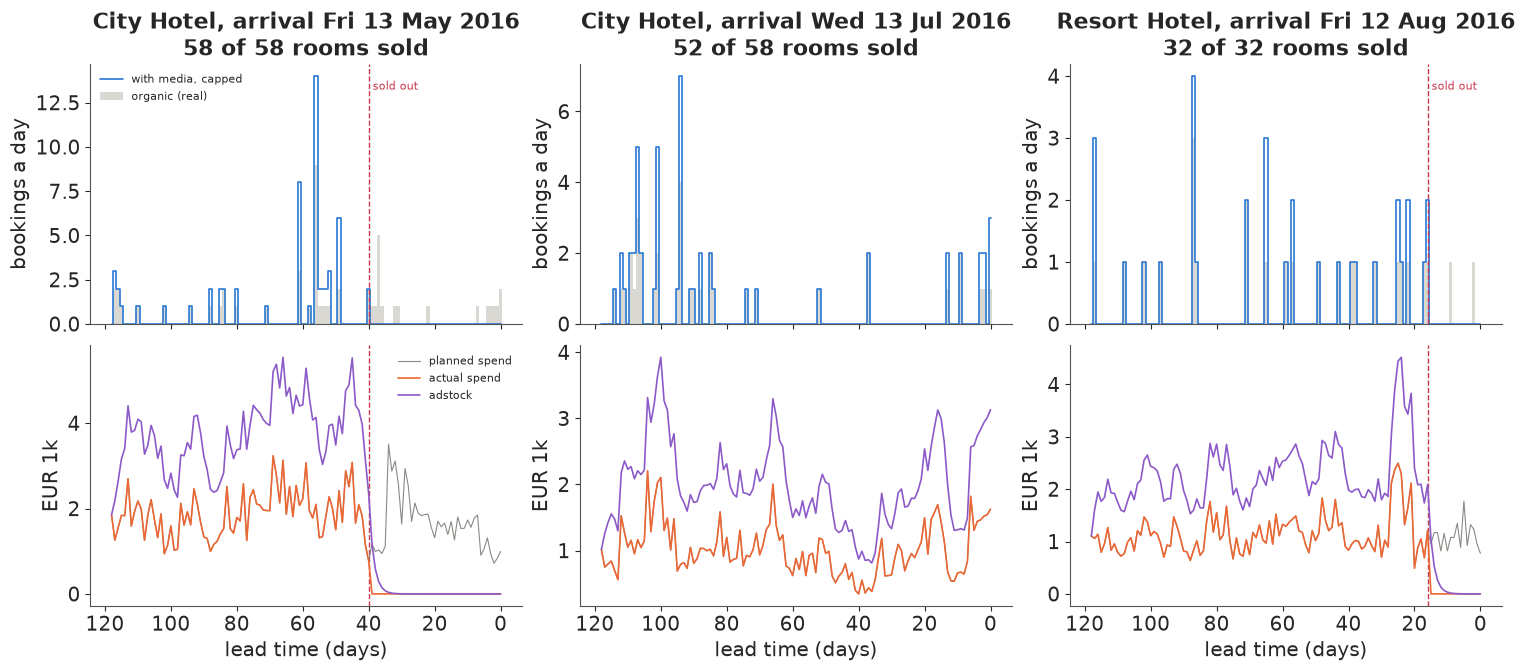

In [8]:
sp_demo = spend_plan("size", 2024, flight_sd=0.3)
Dd = simulate(sp_demo, 2025, capped=True, stop=True)
print(f"demo world (capacity, spend stops at sell-out, budget follows size): {Dd['sold'].mean():.0%} of events "
      f"sell out; bookings {Dd['Ytot'].sum():,.0f} against {TOT0.sum():,} organic (x{Dd['Ytot'].sum() / TOT0.sum():.2f})")
print(f"log of the planner's forecast (leave-one-out group mean) against log realised organic total: correlation "
      f"{np.corrcoef(np.log(FC), np.log(np.maximum(TOT0, 1)))[0, 1]:.2f}")
fig, axes = plt.subplots(2, 3, figsize=(15, 6.6), sharex=True)
show = [int(np.flatnonzero(Dd["sold"] & (HOTEL == 0))[5]), int(np.flatnonzero(~Dd["sold"] & (HOTEL == 0))[40]),
        int(np.flatnonzero(Dd["sold"] & (HOTEL == 1))[12])]
for c, e in enumerate(show):
    ax = axes[0, c]
    ax.bar(LEAD, Y0[e], width=1.0, color=LIGHT, label="organic (real)")
    ax.step(LEAD, Dd["y2"][e], where="mid", color=BLUE, lw=1.2, label="with media, capped")
    ax.set(title=f"{HOTELS[HOTEL[e]]}, arrival {ADATE[e]:%a %d %b %Y}\n{Dd['Ytot'][e]:.0f} of {CAP[e]:.0f} rooms sold",
           ylabel="bookings a day")
    if Dd["sold"][e]:
        so = LEAD[np.flatnonzero(Dd["cens2"][e])[0]]
        for ax_ in axes[:, c]:
            ax_.axvline(so, color=RED, lw=1, ls="--")
        ax.text(so, ax.get_ylim()[1] * 0.9, " sold out", color=RED, fontsize=8)
    ax = axes[1, c]
    ax.plot(LEAD, sp_demo["plan"][e], color=MUTED, lw=0.8, label="planned spend")
    ax.plot(LEAD, Dd["spend2"][e], color=ORANGE, lw=1.2, label="actual spend")
    ax.plot(LEAD, Dd["A2"][e], color=PURPLE, lw=1.2, label="adstock")
    ax.set(xlabel="lead time (days)", ylabel="EUR 1k")
    ax.invert_xaxis()
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8);

In this world 35% of events sell out, and total bookings rise by 17% over the real ones: less than
the 35% a day's lift suggests, because sold-out events cannot take their share. In the two
sold-out events (left and right) spend falls to zero at the dashed line and adstock decays over
the next few days, while sales are zero; the middle event never fills. That picture holds the
first trap: after a sell-out, a model that keeps the rows sees days with **no spend and no
sales**, and reads them as evidence that spend sells rooms. The size budgets here follow realised
totals exactly. The planner's forecast, the mean of the other events of the same hotel, month and
weekday type, correlates only 0.68 with realised size on the log scale; it is also the target the
reactive plan paces against.

## C · How each spending habit fools the t-minus model

We need many fits - nine kinds of world, three worlds each, several estimators per world - so here
we use a fast stand-in for the Bayesian model: Poisson maximum likelihood with event effects, a
lead-time curve and $\beta$, solved with L-BFGS on a sparse design matrix in about a second. With
event **fixed effects** it is the classical panel estimator; with a Gaussian penalty of sd $\tau$
on the event effects it is the **posterior mode** of the random-intercept model at that $\tau$,
estimated from the spread of the fixed effects. Both use only what the analyst has. The two
control worlds have random spend, with and without a room limit. The seven habits are stopping
spend at sell-out, reactive pacing, seasonal spend, platform spend, seasonal platform spend, spend
timed to the type's curve, and budgets that follow size. The baseline, labelled **fixed effects**,
is the t-minus model of the opening with a free effect per event and one pooled curve. Most habits
work through variation within events, which pooled and unpooled models share, so we grade them
with fixed effects; the naive hierarchical model, "random intercepts", sits beside it in the
sell-out and seasonal worlds to show this, and in the size world, where it adds a trap of its own.
Part D fits it in PyMC.

Each fix adds one thing. **Censoring** drops the days after a sell-out and gives the sell-out day
the likelihood of "at least $R$ more", $R$ the rooms left: $P(Y \ge R) = 1 - F(R - 1)$ for a
discrete distribution function $F$; dropping the sell-out day as well is the cruder version.
**Pacing controls** add the event's shortfall against its target, its past week's sales rate, or
both, or else the adstock of the rule's multiplier $e^{2g}$. An **instrument** uses only the
rule's random factor. **Calendar terms** are week-of-booking plus day-of-week effects, or one
effect per booking date. **Curves by type** give each event type its own lead curve. The
**Mundlak** term makes an event's log mean adstock a predictor of its random intercept (Mundlak
1978; part D). The random-spend worlds also report the Poisson standard error of $\beta$ and a
cluster-robust one that lets an event's days be correlated.

In [9]:
def dummies(codes):
    _, inv = np.unique(codes, return_inverse=True)
    return sp.csr_matrix((np.ones(len(inv)), (np.arange(len(inv)), inv)))


def fit_poisson(D, rows, curve="common", calendar=None, controls=(), censor=False, event="fe", tau=None,
                mundlak=False, se=False, full=False):
    """Poisson regression of daily bookings on adstock. Event intercepts are fixed effects (event='fe') or
    random effects with sd tau (event='re': the posterior mode of a random-intercept model); lead curve
    'common' or by 'type'; calendar None, 'week' (week + day-of-week) or 'day' (one effect per booking date).
    censor: the sell-out day counts as 'at least the remaining rooms'. mundlak: log mean adstock per event."""
    y = D["y"][rows]
    cols = [D["A"][rows]] + [D[c][rows] for c in controls]
    evr = D["ev"][rows]
    if mundlak:
        mbar = np.bincount(evr, weights=D["A"][rows], minlength=E) / np.maximum(1, np.bincount(evr, minlength=E))
        cols.append(np.log(np.maximum(mbar, 1e-3))[evr])
    k = len(cols)
    blocks = [sp.csr_matrix(np.column_stack(cols)), dummies(evr)]
    n_ev = blocks[1].shape[1]
    if event == "re":
        blocks += [sp.csr_matrix(np.ones((len(y), 1))), dummies(D["etype"][rows])[:, 1:]]
    blocks.append(dummies(D["lead"][rows] if curve == "common" else D["etype"][rows] * 1000 + D["lead"][rows])[:, 1:])
    if calendar == "day":
        blocks.append(dummies(D["date"][rows])[:, 1:])
    elif calendar == "week":
        blocks += [dummies(D["week"][rows])[:, 1:], dummies(D["dow"][rows])[:, 1:]]
    X = sp.hstack(blocks).tocsr()
    XT = X.T.tocsr()
    pen = np.full(X.shape[1], 1e-3)                       # a whisper of ridge for the aliased calendar terms
    pen[:k] = 0.0
    if event == "re":
        pen[k:k + n_ev] = 0.5 / tau ** 2
    c = D["cens"][rows] if censor else np.zeros(len(y), bool)
    yc = y[c]

    def nll(b):
        eta = np.clip(X @ b, -30, 30)
        lam = np.exp(eta)
        ll, g = y * eta - lam, y - lam
        if c.any():                                       # log P(Y >= r) and its derivative in eta
            lsf = stats.poisson.logsf(yc - 1, lam[c])
            with np.errstate(all="ignore"):
                hz = np.exp(eta[c] + stats.poisson.logpmf(yc - 1, lam[c]) - lsf)
            ll[c], g[c] = lsf, np.where(np.isfinite(hz), hz, yc - lam[c])
        return -ll.sum() + (pen * b * b).sum(), -(XT @ g) + 2 * pen * b

    b0 = np.zeros(X.shape[1])
    m_ = np.bincount(evr, weights=y, minlength=E) / np.maximum(1, np.bincount(evr, minlength=E))
    lm = np.log(m_[np.unique(evr)] + 0.05)
    b0[k:k + n_ev] = lm - (lm.mean() if event == "re" else 0.0)
    if event == "re":
        b0[k + n_ev] = lm.mean()
    res = minimize(nll, b0, jac=True, method="L-BFGS-B", options=dict(maxiter=5000, gtol=1e-7))
    if full:
        return res.x, k, np.unique(evr)
    if not se:
        return res.x[0]
    lam = np.exp(np.clip(X @ res.x, -30, 30))
    H = (XT @ sp.diags(lam) @ X).toarray() + np.diag(2 * pen)
    Hk = np.linalg.solve(H, np.eye(H.shape[0])[:, :1])
    G = (dummies(evr).T @ X.multiply((y - lam)[:, None]).tocsr()).toarray()   # score summed by event
    return res.x[0], float(np.sqrt(Hk[0, 0])), float(np.sqrt(Hk.T @ G.T @ G @ Hk)[0, 0])


def tau_hat(D, rows):
    """Between-event sd of log intercepts within type, from a fixed-effects fit, net of Poisson noise."""
    x, k, ev_u = fit_poisson(D, rows, full=True)
    a = x[k:k + len(ev_u)]
    n = np.bincount(D["ev"][rows], weights=D["y"][rows], minlength=E)[ev_u]
    ok, et = n >= 3, ETYPE[ev_u]
    v = np.mean([a[ok & (et == t)].var() for t in range(4)]) - np.mean(1 / n[ok])
    return float(np.sqrt(max(v, 0.01)))


def fit_iv(D):
    """Reactive pacing: the rule's random factor, read back as spend / e^{2 gap}, as an instrument. Solves the
    moment sum_{e,l} Z_el (q_el - mean_l q_el) = 0, q = y e^{-beta A}, Z = adstock of the centred log factor.
    At the true beta E[q] is the organic rate, and Z is randomised (independent of demand, mean zero), so the
    moment needs neither strict exogeneity nor event effects; subtracting each event's mean only cuts noise."""
    y, A = D["y"].reshape(E, L), D["A"].reshape(E, L)
    lf = np.log(D["spend"].reshape(E, L)) - 2.0 * D["gap"].reshape(E, L)
    Z = adstock(lf - lf.mean())

    def g(b):
        q = y * np.exp(-b * A)
        return (Z * (q - q.mean(1, keepdims=True))).sum()

    return brentq(g, -0.5, 1.0)

In [10]:
R_REP = 3
SCEN = {
    "random spend":                 dict(policy="random"),
    "capacity, spend continues":    dict(policy="random", capped=True),
    "spend stops at sell-out":      dict(policy="random", capped=True, stop=True),
    "reactive pacing":              dict(policy="reactive", reactive=True),
    "seasonal spend":               dict(policy="seasonal"),
    "platform spend":               dict(policy="platform"),
    "platform spend, seasonal":     dict(policy="platform, seasonal"),
    "spend timed to type curve":    dict(policy="curve"),
    "budget follows size":          dict(policy="size", flight_sd=0.3),
}


def scenario_fits(name, D):
    r0 = np.ones(len(D["y"]), bool)
    lv = D["live"]
    if name == "random spend":
        b, se_p, se_c = fit_poisson(D, r0, se=True)
        return {"fixed effects": b, "Poisson se": se_p, "event-cluster se": se_c,
                "type curves + week + dow": fit_poisson(D, r0, curve="type", calendar="week")}
    fe = fit_poisson(D, r0)
    if name == "capacity, spend continues":
        return {"fixed effects": fe, "censored": fit_poisson(D, lv, censor=True)}
    if name == "spend stops at sell-out":
        return {"fixed effects": fe, "random intercepts": fit_poisson(D, r0, event="re", tau=tau_hat(D, r0)),
                "drop sell-out day and after": fit_poisson(D, lv & ~D["cens"]),
                "censored sell-out day": fit_poisson(D, lv, censor=True)}
    if name == "reactive pacing":
        return {"fixed effects": fe, "pace controls": fit_poisson(D, r0, controls=("gap", "lag7")),
                "shortfall only": fit_poisson(D, r0, controls=("gap",)),
                "past week's sales rate only": fit_poisson(D, r0, controls=("lag7",)),
                "control for the rule's multiplier": fit_poisson(D, r0, controls=("Aplan",)),
                "random factor as instrument": fit_iv(D)}
    if name == "seasonal spend":
        return {"fixed effects": fe, "random intercepts": fit_poisson(D, r0, event="re", tau=tau_hat(D, r0)),
                "week + dow": fit_poisson(D, r0, calendar="week"),
                "booking-date effects": fit_poisson(D, r0, calendar="day")}
    if name.startswith("platform spend"):
        return {"fixed effects": fe, "week + dow": fit_poisson(D, r0, calendar="week"),
                "booking-date effects (aliased)": fit_poisson(D, r0, calendar="day")}
    if name == "spend timed to type curve":
        return {"fixed effects": fe, "type curves": fit_poisson(D, r0, curve="type")}
    t = tau_hat(D, r0)
    return {"fixed effects": fe, "random intercepts": fit_poisson(D, r0, event="re", tau=t),
            "random intercepts + Mundlak": fit_poisson(D, r0, event="re", tau=t, mundlak=True)}


t0 = time.time()
rows_ = []
for name, cfg in SCEN.items():
    cfg = dict(cfg)
    pol, fs = cfg.pop("policy"), cfg.pop("flight_sd", 0.0)
    for r in range(R_REP):
        D = simulate(spend_plan(pol, 10_000 + r, flight_sd=fs), 20_000 + r, **cfg)
        for est, v in scenario_fits(name, D).items():
            rows_.append({"scenario": name, "estimator": est, "rep": r, "value": v, "sold": D["sold"].mean()})
scen = pd.DataFrame(rows_)
tab = scen.groupby(["scenario", "estimator"], sort=False).value.agg(["mean", "min", "max"])
tab["x truth"] = tab["mean"] / BETA
n_se = scen.estimator.str.endswith(" se").sum()
print(f"{len(scen) - n_se} estimates of beta (and {n_se} standard errors) from {len(SCEN) * R_REP} worlds in "
      f"{time.time() - t0:.0f} s; truth beta = {BETA}")
print(tab.round(3).to_string())
print("share of events sold out: " + ", ".join(f"{k} {v:.0%}" for k, v in
                                              scen.groupby("scenario", sort=False).sold.mean().items() if v > 0))

87 estimates of beta (and 6 standard errors) from 27 worlds in 98 s; truth beta = 0.15
                                                              mean    min    max  x truth
scenario                  estimator                                                      
random spend              fixed effects                      0.152  0.145  0.165    1.016
                          Poisson se                         0.006  0.006  0.006    0.040
                          event-cluster se                   0.011  0.011  0.011    0.075
                          type curves + week + dow           0.150  0.141  0.166    1.000
capacity, spend continues fixed effects                      0.144  0.131  0.164    0.962
                          censored                           0.150  0.135  0.167    0.997
spend stops at sell-out   fixed effects                      0.316  0.299  0.334    2.104
                          random intercepts                  0.306  0.290  0.325    2.041
             

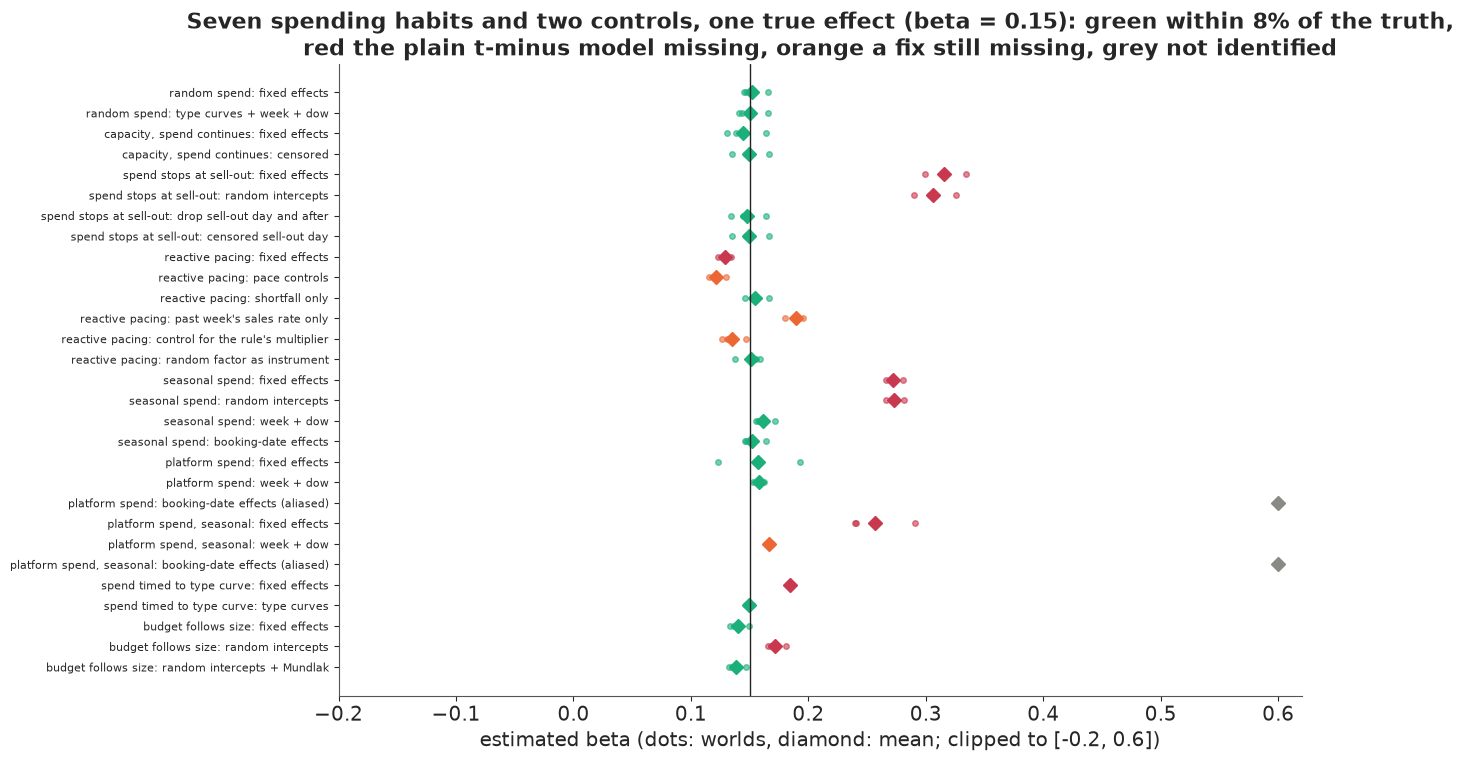

In [11]:
fig, ax = plt.subplots(figsize=(13, 7.5))
plot_rows = tab.drop([i for i in tab.index if "se" in i[1].split()])
ylab, yy = [], 0
for (scn, est), row in plot_rows.iterrows():
    ok = abs(row["mean"] - BETA) < 0.08 * BETA
    col = RED if est in ("fixed effects", "random intercepts") and not ok else (AQUA if ok else ORANGE)
    if est == "booking-date effects (aliased)":
        col = MUTED
    vals = scen[(scen.scenario == scn) & (scen.estimator == est)].value
    ax.plot(vals.clip(-0.2, 0.6), np.full(len(vals), yy), "o", color=col, ms=4, alpha=0.6)
    ax.plot(np.clip(row["mean"], -0.2, 0.6), yy, "D", color=col, ms=7)
    ylab.append(f"{scn}: {est}")
    yy -= 1
ax.axvline(BETA, color=INK, lw=1)
ax.set_yticks(np.arange(0, yy, -1), ylab, fontsize=8)
ax.set(xlim=(-0.2, 0.62), xlabel="estimated beta (dots: worlds, diamond: mean; clipped to [-0.2, 0.6])",
       title=f"Seven spending habits and two controls, one true effect (beta = {BETA}): green within 8% of the truth,\n"
             "red the plain t-minus model missing, orange a fix still missing, grey not identified");

The 87 estimates of $\beta$ take under two minutes. The figure shows the table: red where the
plain t-minus model (fixed effects or random intercepts) misses, orange where a fix still misses,
green within 8% of the truth, grey where $\beta$ is not identified.

**Random spend** is the sanity check. When nobody chooses the spend, the t-minus model recovers
$\beta$ (0.152, worlds 0.145-0.165), with or without type curves and calendar terms. That spread,
about $\pm 0.01$, is the yardstick below: with three worlds per habit, a mean within 0.01 of the
truth cannot be told from it. The Poisson standard error is 0.006, the cluster-robust one 0.011:
real bookings are lumpier than Poisson, so a Poisson likelihood - or a Bayesian model built on
one - reports intervals about half as wide as they should be.

**Capacity alone does little.** With rooms limited and spend still running after the sell-out,
fixed effects give 0.144. The days after a sell-out have zero sales whatever the spend, which
dilutes the estimate a little; censoring removes that (0.150).

**Stopping spend at sell-out doubles the estimate**: 0.316 (0.30-0.33), 2.1 times the truth, and
random intercepts are fooled as much (0.306). Before a sell-out an event has spend and sales;
after it, neither, so within the event spend and sales move together for a reason that has nothing
to do with media. Dropping the sell-out day and everything after gives 0.148, the censored
likelihood 0.150. On daily data the two are hard to tell apart, because the sell-out day is one
of 119.

**Reactive pacing pulls $\beta$ down by a seventh** (0.129). The rule spends more on events that
are behind their target, so extra spend tends to land on days that are still slow, and today's
sales move tomorrow's spend. Fixed-effects Poisson needs spend to be unrelated to an event's
demand surprises on every day, past and future, and that feedback breaks it even though surprises
here fade within weeks. Controlling for what the rule saw is no reliable cure, because the
controls are themselves driven by the event's past surprises. The shortfall alone brings $\beta$
to 0.155; the past week's sales rate alone pushes it to 0.189; the two together give 0.121, worse
than none. The adstock of the rule's multiplier helps a little (0.135). Using only the part of
spend the rule did not choose works. The rule is known, so its random factor can be read back as
spend over $e^{2g}$. That factor was drawn at random, independent of demand by construction, so a
moment condition built from it needs neither strict exogeneity nor event effects (subtracting each
event's mean only reduces noise). It gives 0.151, with a wider spread between worlds
(0.138-0.159).

**Seasonal spend nearly doubles the estimate** (0.272, and 0.273 with random intercepts): with no
calendar terms the model credits media with the market's busy weeks. Week and day-of-week effects
leave +7% (0.161). The spending index is a seven-day mean that slides day by day, while week terms
are fixed blocks, so within a week spend still follows demand. And because the index was built
from these same bookings, it follows their noise too. One effect per booking date restores 0.152.
Calendar terms have to live on the booking-date clock.

**Platform spend is not identified once booking dates have their own effects.** A brand campaign
that is the same for every event on sale makes adstock a function of the booking date alone,
exactly a combination of the date dummies; the printed 0.88 and 0.85 are only the tie-break of the
fitter's small ridge on calendar terms, greyed out in the figure. Week terms identify $\beta$ only
if demand does not move within a week the way the campaign does: they give 0.158 when the series
is noise around a constant, and +11% (0.166) when it follows the season, against 0.257 for fixed
effects alone.

**Spend timed to each type's booking curve inflates $\beta$ by about a fifth** (0.184) when one
pooled curve is fitted. The pooled curve is too flat for resort weekday arrivals and too steep for
the city hotel, and the part it misses lines up with spend. Curves by type fix it (0.149). The
t-minus clock is right; one curve for every kind of event is not.

**When budgets follow event size, random intercepts read size as return on spend.** Fixed effects
use only variation within events and give 0.140 (0.134-0.149); part D runs seven more of these
worlds and finds the shortfall is the luck of three. Random intercepts give 0.171, 1.22 times the
fixed-effects answer in the same worlds, and the Mundlak term brings them back to it (0.138). Part
D explains the trap.

## D · The hierarchical trap, in PyMC

The decision world of the rest of the notebook switches several habits on at once, as a real
platform would: rooms are limited, spend stops at sell-out, budgets follow event size, and spend
comes in weekly flights (log sd 0.3). It is the demo world of part B, with the same seeds. For
PyMC we work in **lead weeks** - 17 per event - and take 150 events from each hotel, 300 in all.
Weekly bins need care at the sell-out.

When an event sells out during week $w$ with $R$ rooms left at its start, "it sold out some day
that week" is the same event as "the week's demand at the **planned** spend would have been at
least $R$", since spend changes only after the sell-out. The planned week's adstock is therefore
the covariate to use; the mean adstock over the days still on sale approximates it, and the cell
compares the two. Averaging the actual adstock over all seven days, zeros after the sell-out
included, is wrong: that covariate depends on when the event sold out, which is the outcome.
PyMC's `pm.Censored(dist, upper=R)` evaluated at $R$ returns $\log P(Y \ge R)$ for a discrete
distribution, the right term; it is tempting to "correct" the bound to $R - 1$. The cell checks it
against SciPy.

In [12]:
SP_DEC = spend_plan("size", 2024, flight_sd=0.3)
DEC = simulate(SP_DEC, 2025, capped=True, stop=True)
y_d, A_d, lv_d, cs_d = DEC["y2"], DEC["A2"], DEC["live2"], DEC["cens2"]
yw = y_d.reshape(E, W, 7).sum(2)
lvd = lv_d.reshape(E, W, 7)
Aw_live = (A_d.reshape(E, W, 7) * lvd).sum(2) / np.maximum(lvd.sum(2), 1)   # mean adstock over days on sale
cens_w = cs_d.reshape(E, W, 7).any(2)
live_w = lvd[:, :, 0]
rem_w = CAP[:, None] - np.concatenate([np.zeros((E, 1)), np.cumsum(yw, 1)[:, :-1]], 1)
calw_all = BDATE.reshape(E, W, 7)[:, :, 3] // 7
rs_ = np.random.default_rng(7)
EV = np.sort(np.concatenate([rs_.choice(np.flatnonzero(HOTEL == h), 150, replace=False) for h in (0, 1)]))
nE = len(EV)
calw = calw_all[EV] - calw_all[EV].min()
n_cal = int(calw.max()) + 1
print(f"decision world: {DEC['sold'].mean():.0%} of events sell out; PyMC subset {nE} events, "
      f"{nE * W:,} event-weeks ({live_w[EV].sum():,} on sale, {cens_w[EV].sum()} sell-out weeks), {n_cal} calendar weeks")
ones_ = np.ones(len(DEC["y"]), bool)
t_dec = tau_hat(DEC, DEC["live"])
print(f"fast estimates on all {E:,} events, daily data: fixed effects, every day kept {fit_poisson(DEC, ones_):.3f}; "
      f"censored fixed effects {fit_poisson(DEC, DEC['live'], censor=True):.3f}; censored random intercepts "
      f"{fit_poisson(DEC, DEC['live'], censor=True, event='re', tau=t_dec):.3f}, + Mundlak "
      f"{fit_poisson(DEC, DEC['live'], censor=True, event='re', tau=t_dec, mundlak=True):.3f}")
A_plan_w = adstock(SP_DEC["plan"]).reshape(E, W, 7).mean(2)              # planned adstock, all seven days
EVW = np.broadcast_to(np.arange(E)[:, None], (E, W)).ravel()
for lab, Aw in [("all seven days, zeros after the sell-out", A_d.reshape(E, W, 7).mean(2)),
                ("all seven days of PLANNED spend in the sell-out week", np.where(cens_w, A_plan_w, Aw_live)),
                ("the days on sale", Aw_live)]:
    Dw = dict(y=np.where(cens_w, rem_w, yw).ravel(), A=Aw.ravel(), cens=cens_w.ravel(),
              lead=np.broadcast_to(np.arange(W), (E, W)).ravel(), ev=EVW)
    print(f"weekly data, censored fixed effects, a week's adstock averaged over {lab}: "
          f"{fit_poisson(Dw, live_w.ravel(), censor=True):.3f}")
in_ev = np.isin(np.arange(E), EV)[:, None]
print(f"weekly data, days on sale: sell-out week dropped instead of censored {fit_poisson(Dw, (live_w & ~cens_w).ravel()):.3f}")
in_d = np.isin(DEC["ev"], EV)
Dall = dict(Dw, y=yw.ravel(), A=Aw_live.ravel(), cens=np.zeros(E * W, bool))
print(f"the {nE} PyMC events: censored fixed effects, daily {fit_poisson(DEC, DEC['live'] & in_d, censor=True):.3f}, "
      f"weekly {fit_poisson(Dw, (live_w & in_ev).ravel(), censor=True):.3f}; censored random intercepts, daily "
      f"{fit_poisson(DEC, DEC['live'] & in_d, censor=True, event='re', tau=t_dec):.3f}; fixed effects with every "
      f"week kept, weekly {fit_poisson(Dall, np.broadcast_to(in_ev, (E, W)).ravel()):.3f}")
fe_size = np.array([fit_poisson(simulate(spend_plan("size", 10_000 + r, flight_sd=0.3), 20_000 + r),
                                np.ones(E * L, bool)) for r in range(10)])
print(f"budget follows size, ten worlds (part C's three and seven more): fixed effects mean {fe_size.mean():.3f}, "
      f"Monte Carlo se {fe_size.std(ddof=1) / np.sqrt(10):.3f}, range {fe_size.min():.3f}-{fe_size.max():.3f}")
d_ = pm.Censored.dist(pm.NegativeBinomial.dist(mu=3.0, alpha=2.0), lower=None, upper=5)
print(f"pm.Censored(NegBin(mu=3, alpha=2), upper=5) at 5: log p = {float(pm.logp(d_, 5).eval()):.4f}; SciPy: "
      f"log P(Y >= 5) = {stats.nbinom.logsf(4, 2.0, 2 / 5):.4f}, log P(Y > 5) = {stats.nbinom.logsf(5, 2.0, 2 / 5):.4f}")

decision world: 35% of events sell out; PyMC subset 300 events, 5,100 event-weeks (4,917 on sale, 102 sell-out weeks), 87 calendar weeks


fast estimates on all 976 events, daily data: fixed effects, every day kept 0.405; censored fixed effects 0.137; censored random intercepts 0.186, + Mundlak 0.138


weekly data, censored fixed effects, a week's adstock averaged over all seven days, zeros after the sell-out: 0.111


weekly data, censored fixed effects, a week's adstock averaged over all seven days of PLANNED spend in the sell-out week: 0.132


weekly data, censored fixed effects, a week's adstock averaged over the days on sale: 0.133


weekly data, days on sale: sell-out week dropped instead of censored 0.126


the 300 PyMC events: censored fixed effects, daily 0.165, weekly 0.162; censored random intercepts, daily 0.213; fixed effects with every week kept, weekly 0.390


budget follows size, ten worlds (part C's three and seven more): fixed effects mean 0.149, Monte Carlo se 0.004, range 0.133-0.163


pm.Censored(NegBin(mu=3, alpha=2), upper=5) at 5: log p = -1.4555; SciPy: log P(Y >= 5) = -1.4555, log P(Y > 5) = -1.8412


In this world 35% of events sell out, and 102 of the subset's 4,917 event-weeks on sale are
sell-out weeks. On all 976 events with daily data, fixed effects that keep every day give 0.405,
nearly three times the truth, because spend stops at every sell-out; censoring brings them to
0.137, within the noise of a single world: over ten worlds with these budgets, fixed effects
average 0.149 (Monte Carlo standard error 0.004, worlds 0.133-0.163). Random intercepts on the
same censored data give 0.186, 1.36 times the fixed-effects answer, and the Mundlak term gives
0.138, back on it.

On weekly data, the planned adstock over the whole sell-out week gives 0.132 and the mean over the
days on sale 0.133, so the approximation costs nothing here; averaging actual adstock over all
seven days gives 0.111. Dropping the sell-out week instead of censoring it gives 0.126, which
agrees with censoring within the world-to-world noise. The 300 events PyMC will see give 0.162 on
weekly data and 0.165 on daily data. The subset alone moves the estimate by about 0.03, so we
compare the PyMC models with fixed effects on these same 300 events, not with the truth. The bound
check agrees with SciPy to four decimals.

Now the hierarchical model in PyMC, built up in three steps on the weekly data of the 300 events.
Each has non-centred random intercepts $a_e = \mu_0 + \sigma_a z_e$, a zero-sum lead-week curve,
and $\beta \sim N(0, 0.5)$, with a Poisson likelihood. The first keeps every week, including those
after a sell-out. The second drops the weeks after the sell-out week and censors the sell-out
week. The third adds the Mundlak term.

In [13]:
def report(name, idata, t, vars_):
    st = idata.sample_stats
    b = idata.posterior["beta"].to_numpy().ravel()
    rh = max(float(az.rhat(idata.posterior[v]).max()) for v in vars_)
    es = min(min(float(az.ess(idata.posterior[v], method=k).min()) for k in ("bulk", "tail")) for v in vars_)
    lo, hi = np.quantile(b, [0.03, 0.97])
    return {"model": name, "beta mean": b.mean(), "sd": b.std(), "3%": lo, "97%": hi, "seconds": t,
            "divergences": int(st["diverging"].sum()), "max r_hat": rh, "min ESS (bulk, tail)": es}


EE = np.broadcast_to(np.arange(nE)[:, None], (nE, W))
WK = np.broadcast_to(np.arange(W), (nE, W))
coords = dict(event=np.arange(nE), leadweek=np.arange(W), type=TYPES, calweek=np.arange(n_cal), hotel=HOTELS)


def poisson_ri(keep, censor, mundlak):
    """Random-intercept Poisson on weekly bookings: one population of events, independent of spend unless
    the Mundlak term is in."""
    e_, w_ = EE[keep], WK[keep]
    yv, Av = yw[EV][keep], Aw_live[EV][keep]
    cv = cens_w[EV][keep] if censor else np.zeros(len(yv), bool)
    rv = rem_w[EV][keep]
    mbar = np.bincount(e_, weights=Av, minlength=nE) / np.maximum(1, np.bincount(e_, minlength=nE))
    lm_c = np.log(np.maximum(mbar, 1e-3))
    lm_c -= lm_c.mean()
    with pm.Model(coords=coords) as m:
        mu0 = pm.Normal("mu0", np.log(yv.mean()), 1.0)
        sd_a = pm.HalfNormal("sd_a", 0.5)
        z = pm.Normal("z", 0.0, 1.0, dims="event")
        a_ev = mu0 + sd_a * z + (pm.Normal("pi", 0.0, 1.0) * lm_c if mundlak else 0.0)
        curve = pm.ZeroSumNormal("curve", 1.0, dims="leadweek")
        beta = pm.Normal("beta", 0.0, 0.5)
        mu = pt.exp(a_ev[e_] + curve[w_] + beta * Av)
        u_, c_ = np.flatnonzero(~cv), np.flatnonzero(cv)
        pm.Poisson("y", mu[u_], observed=yv[u_])
        if censor:
            pm.Censored("y_soldout", pm.Poisson.dist(mu[c_]), lower=None, upper=rv[c_], observed=rv[c_])
    return m


ladder, fits = [], {}
for name, keep, cens_, mund in [("naive: every week kept", np.ones((nE, W), bool), False, False),
                                ("after sell-out dropped, sell-out week censored", live_w[EV], True, False),
                                ("... plus the Mundlak term", live_w[EV], True, True)]:
    t0 = time.time()
    with poisson_ri(keep, cens_, mund):
        fits[name] = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    ladder.append(report(name, fits[name], time.time() - t0, ["beta", "mu0", "sd_a", "curve", "z"] + ["pi"] * mund))
print(pd.DataFrame(ladder).round(3).to_string(index=False))

                                         model  beta mean    sd    3%   97%  seconds  divergences  max r_hat  min ESS (bulk, tail)
                        naive: every week kept      0.403 0.007 0.389 0.417    4.901            0      1.010              1274.604
after sell-out dropped, sell-out week censored      0.254 0.013 0.230 0.279    5.095            0      1.012               607.562
                     ... plus the Mundlak term      0.164 0.012 0.142 0.185    5.620            0      1.007              1427.930


across the 300 events: log organic bookings on log mean adstock, slope 0.93, correlation 0.95


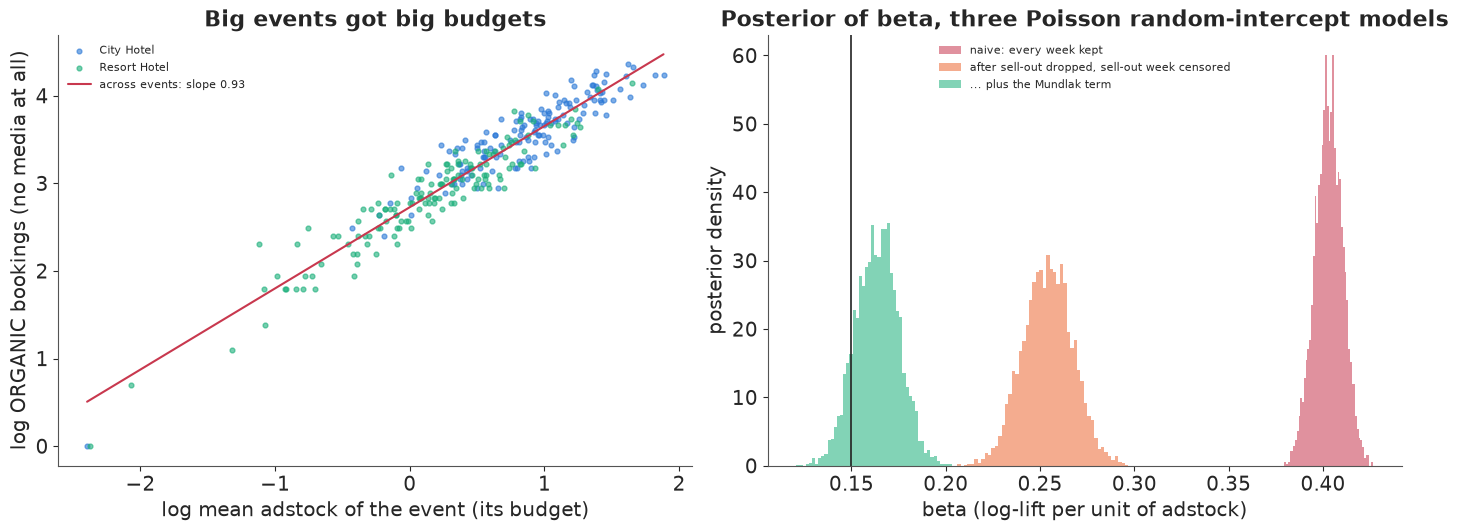

In [14]:
mb = np.bincount(EE[live_w[EV]], weights=Aw_live[EV][live_w[EV]], minlength=nE) / live_w[EV].sum(1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
for h, col in [(0, BLUE), (1, AQUA)]:
    m_ = HOTEL[EV] == h
    ax.scatter(np.log(mb[m_]), np.log(TOT0[EV][m_]), s=12, color=col, alpha=0.6, label=HOTELS[h])
xs = np.linspace(np.log(mb).min(), np.log(mb).max(), 10)
bb_ = np.polyfit(np.log(mb), np.log(TOT0[EV]), 1)
print(f"across the {nE} events: log organic bookings on log mean adstock, slope {bb_[0]:.2f}, correlation "
      f"{np.corrcoef(np.log(mb), np.log(TOT0[EV]))[0, 1]:.2f}")
ax.plot(xs, np.polyval(bb_, xs), color=RED, lw=1.5, label=f"across events: slope {bb_[0]:.2f}")
ax.set(xlabel="log mean adstock of the event (its budget)", ylabel="log ORGANIC bookings (no media at all)",
       title="Big events got big budgets")
ax.legend(fontsize=8)
ax = axes[1]
for i, (nm, f_) in enumerate(fits.items()):
    ax.hist(f_.posterior["beta"].to_numpy().ravel(), bins=50, density=True, alpha=0.55, color=[RED, ORANGE, AQUA][i],
            label=nm)
ax.axvline(BETA, color=INK, lw=1.2)
ax.set(xlabel="beta (log-lift per unit of adstock)", ylabel="posterior density",
       title="Posterior of beta, three Poisson random-intercept models")
ax.legend(fontsize=8);

Each fit takes about five seconds, with no divergences, r_hat at most about 1.01 and over 600
effective draws (the smaller of bulk and tail ESS). By every diagnostic these are healthy
posteriors. Two of them are healthy posteriors of the wrong number.

**Failure 1: the naive hierarchical model.** Keeping every week, $\beta$ is 0.403 with a 94%
interval of 0.389-0.417: almost three times the truth, and sure of it.

**Failure 2: the random intercepts.** Dropping the post-sell-out weeks and censoring the sell-out
week removes the sell-out trap, and $\beta$ falls to 0.254 (0.230-0.279), still 1.6 times the
fixed-effects answer on the same events (0.162) and 1.7 times the truth. The model assumes $a_e
\sim N(\mu_0, \sigma_a)$ **independently of everything else in it, spend included**. The left
panel shows how false that is: events with bigger budgets were bigger before any media, with a
slope of 0.93 on the log scale and a correlation of 0.95 (our budgets know each event's realised
size; a forecast-based budget would leak less). A fixed-effects model learns $\beta$ only from
changes within events. A random-intercept model pulls each event's level toward the population
mean, so a big event's high sales are partly "explained" by its big budget: the slope across
events leaks into $\beta$, the more so the less spend varies within events. Against fixed effects
in the same data, the trap grows from 1.22 in part C's size worlds to 1.36 in this world's daily
data and 1.6 in its weekly data. The subset is not the cause: on the same 300 events with daily
data the fast estimate gives 1.29 (0.213 against 0.165). The rest comes with the weekly bins,
which average away day-to-day variation in spend, or with the PyMC model's own estimate of
$\sigma_a$; we have not separated those two.

**The fix: the Mundlak term.** Mundlak (1978) showed that in a linear model, letting the random
intercept depend on the group mean of the regressor makes the random-effects slope equal to the
within-group (fixed-effects) one, while keeping the partial pooling of the levels. We use a
version of it, a correlated random effect,

$$a_e = \mu_0 + \pi \log \bar A_e + \sigma_a z_e,$$

an approximation outside the linear case, with the **log** of the mean adstock over the weeks on
sale, since budgets act on log sales. With it, $\beta$ is 0.164 (0.142-0.185), next to the
fixed-effects 0.162 on the same events, an interval that covers the truth. It is still too narrow,
as part C's standard errors warned: a Poisson likelihood on lumpy bookings is overconfident
whatever its mean structure.

Put together, the naive model's 0.403 has two layers. Fixed effects that keep every week give
0.390 on these events, so most of it is the sell-out trap: the empty weeks after a sell-out, with
no spend and no sales. Censoring them leaves 0.254, and what remains is the random-intercept trap,
size read as return on spend, which the Mundlak term removes (0.164). Part G shows what the two do
to a decision: the same naive model sends the next euro to events that sell out anyway.

## E · A better model

The three Poisson models leave out what part A showed about the real baseline: counts more
variable than Poisson, curves that differ by type, and calendar swings. The better model puts all
of it in, with the two fixes that removed most of the bias:

$$\begin{aligned}
Y_{ew} &\sim \text{NegBin}(\mu_{ew}, \phi) \text{ for weeks on sale before the sell-out week}, \qquad
Y_{ew} \ge R_{ew} \text{ in the sell-out week}, \\
\log \mu_{ew} &= a_e + c_w + \sigma_c\, \delta_{\text{type}(e), w} + g_{d(e,w)} + \beta\, \bar A_{ew}, \\
a_e &= \mu_0 + \mu_{\text{type}(e)} + \gamma_{\text{hotel}(e)}\, t_e + \pi\, \log \bar A_e + \sigma_a z_e, \\
g &= P\,\text{cumsum}(\sigma_g\, \epsilon), \qquad \epsilon_k \sim N(0, 1).
\end{aligned}$$

The lead-week curve has a common part $c_w$ and type deviations $\delta$, both zero-sum (the
deviations over lead weeks and over types), shrunk by $\sigma_c$: partial pooling of curves. The
calendar effect $g$ is a weekly Gaussian random walk on the booking week of each event-week's
middle day, 87 weeks, and $P$ projects out its level and linear trend. That is how we handle the
age-period-cohort line: a linear trend in booking dates is a trend in arrival dates plus one in
lead weeks. The free curve carries the second, and a linear trend $\gamma_h t_e$ in arrival date
(years) per hotel carries the first; without it, partially pooled event effects could not absorb a
trend and the projection would quietly assume there is none. $\beta$ is unaffected, since adstock
is not a linear function of the clocks. Priors: $\beta \sim N(0, 0.5)$, from a large negative
effect to a fourfold rise in sales at a typical adstock; $\sigma_a \sim$ HalfNormal(0.5),
$\sigma_c \sim$ HalfNormal(0.3), $\sigma_g \sim$ HalfNormal(0.2) for the walk's weekly step,
$\gamma_h \sim N(0, 0.5)$, $\pi \sim N(0, 1)$, $\mu_{\text{type}}$ zero-sum with scale 0.5, and
the shape $\phi \sim$ Gamma(2, 0.2).

One practical lesson: pay the censored likelihood **only on the censored rows**. Wrapping every
row in `pm.Censored`, with an infinite bound where the event did not sell out, is correct, but
makes every row evaluate the negative binomial's CDF and its gradients. Splitting the rows gives
the same log density; the cell times one gradient of each.

In [15]:
keep = live_w[EV]
rows_e, rows_w = np.nonzero(keep)
yB, AB, cB, rB = yw[EV][keep], Aw_live[EV][keep], cens_w[EV][keep], rem_w[EV][keep]
tB, calB = ETYPE[EV][rows_e], calw[keep]
mbar = np.bincount(rows_e, weights=AB, minlength=nE) / np.maximum(1, np.bincount(rows_e, minlength=nE))
LM_C = np.log(np.maximum(mbar, 1e-3)) - np.log(np.maximum(mbar, 1e-3)).mean()
T_ARR = (ADATE[EV] - ADATE[EV].min()).days.to_numpy() / 365.25
T_ARR = T_ARR - T_ARR.mean()                               # arrival date in years, centred
unc, cen = np.flatnonzero(~cB), np.flatnonzero(cB)
tt = np.arange(n_cal) - (n_cal - 1) / 2
Q = np.column_stack([np.ones(n_cal), tt])
P_DETREND = np.eye(n_cal) - Q @ np.linalg.pinv(Q)        # removes a level and a linear trend from the walk

def build_better(split=True):
    with pm.Model(coords=coords) as m:
        mu0 = pm.Normal("mu0", np.log(yB.mean()), 1.0)
        mu_type = pm.ZeroSumNormal("mu_type", 0.5, dims="type")
        pi = pm.Normal("pi", 0.0, 1.0)                      # Mundlak: how size goes with budget
        sd_a = pm.HalfNormal("sd_a", 0.5)
        z = pm.Normal("z", 0.0, 1.0, dims="event")
        trend = pm.Normal("trend", 0.0, 0.5, dims="hotel")   # per-hotel trend in arrival date (log rate a year)
        a_ev = pm.Deterministic("a_ev", mu0 + mu_type[ETYPE[EV]] + trend[HOTEL[EV]] * T_ARR + pi * LM_C + sd_a * z,
                                dims="event")
        curve = pm.ZeroSumNormal("curve", 1.0, dims="leadweek")
        sd_tc = pm.HalfNormal("sd_tc", 0.3)
        tc_z = pm.ZeroSumNormal("tc_z", 1.0, dims=("type", "leadweek"), n_zerosum_axes=2)
        sd_cal = pm.HalfNormal("sd_cal", 0.2)
        cal_innov = pm.Normal("cal_innov", 0.0, 1.0, dims="calweek")
        cal = pm.Deterministic("cal", pt.dot(P_DETREND, pt.cumsum(cal_innov) * sd_cal), dims="calweek")
        beta = pm.Normal("beta", 0.0, 0.5)
        alpha_nb = pm.Gamma("alpha_nb", 2.0, 0.2)
        mu = pt.exp(a_ev[rows_e] + curve[rows_w] + sd_tc * tc_z[tB, rows_w] + cal[calB] + beta * AB)
        if split:                                           # only the sell-out weeks pay for the NegBin CDF
            pm.NegativeBinomial("y", mu=mu[unc], alpha=alpha_nb, observed=yB[unc])
            pm.Censored("y_soldout", pm.NegativeBinomial.dist(mu=mu[cen], alpha=alpha_nb), lower=None,
                        upper=rB[cen], observed=rB[cen])
        else:                                               # every row censored, at +inf when not sold out
            pm.Censored("y", pm.NegativeBinomial.dist(mu=mu, alpha=alpha_nb), lower=None,
                        upper=np.where(cB, rB, np.inf), observed=np.where(cB, rB, yB))
    return m


def grad_ms(m, n=10):
    """Milliseconds per log-density + gradient evaluation at the initial point."""
    f = m.logp_dlogp_function(ravel_inputs=True)
    f.set_extra_values({})
    x = DictToArrayBijection.map(m.initial_point()).data
    f(x)
    t = time.time()
    for _ in range(n):
        f(x)
    return (time.time() - t) / n * 1e3


better = build_better()
print(f"{len(yB):,} event-weeks on sale: {len(unc):,} uncensored, {len(cen)} censored sell-out weeks")
print(f"one log-density + gradient: split likelihood {grad_ms(better, 50):.2f} ms; every row censored "
      f"{grad_ms(build_better(split=False)):.2f} ms")

with better:
    prior = pm.sample_prior_predictive(500, random_seed=RANDOM_SEED)
pp_y = prior.prior_predictive["y"].to_numpy().reshape(500, -1)
pb = prior.prior["beta"].to_numpy().ravel()
print("prior predictive weekly bookings (uncensored weeks), 5/50/95%: "
      + " / ".join(f"{v:,.0f}" for v in np.percentile(pp_y, [5, 50, 95]))
      + "; observed: " + " / ".join(f"{v:.0f}" for v in np.percentile(yB[unc], [5, 50, 95])))
print("prior draws whose mean weekly count is within a factor 3 of the observed mean: "
      f"{np.mean(np.abs(np.log(pp_y.mean(1) / yB[unc].mean())) < np.log(3)):.0%}")
print("prior multiplier of sales at an adstock of 2, 5/50/95%: "
      + " / ".join(f"{v:.2f}" for v in np.percentile(np.exp(2 * pb), [5, 50, 95])))
print(f"prior calendar walk: step size sd_cal median {np.median(prior.prior['sd_cal'].to_numpy()):.2f}; detrended walk, "
      f"sd across weeks median {np.median(prior.prior['cal'].to_numpy().reshape(500, -1).std(1)):.2f}")

4,917 event-weeks on sale: 4,815 uncensored, 102 censored sell-out weeks


one log-density + gradient: split likelihood 0.67 ms; every row censored 3.72 ms


prior predictive weekly bookings (uncensored weeks), 5/50/95%: 0 / 2 / 65; observed: 0 / 1 / 8
prior draws whose mean weekly count is within a factor 3 of the observed mean: 38%
prior multiplier of sales at an adstock of 2, 5/50/95%: 0.19 / 0.97 / 4.72
prior calendar walk: step size sd_cal median 0.13; detrended walk, sd across weeks median 0.27


The split pays: a gradient costs about 0.7 ms against 3.7 ms with every row censored.

The prior predictive is broad without being absurd. Weekly counts reach 65 at the 95th percentile,
against an observed 8, and 38% of prior draws put the average week within a factor of three of the
observed one. Media's multiplier on a typical week's sales runs from 0.19 to 4.7 between the 5th
and 95th percentiles, centred on 1: the prior does not say whether media works, and allows it to
hurt. The walk's prior puts its weekly step at a median of 0.13 and the detrended walk's spread
across weeks at 0.27, the order of the swings in part A (sd 0.24).

In [16]:
t0 = time.time()
with better:
    idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
t_better = time.time() - t0
ladder.append(report("better: NegBin, type curves, calendar walk, Mundlak, censored", idata, t_better,
                     ["beta", "mu0", "mu_type", "trend", "pi", "sd_a", "z", "curve", "sd_tc", "tc_z", "sd_cal",
                      "cal_innov", "alpha_nb"]))
print(f"sampled in {t_better:.0f} s; tuning steps {idata.posterior.attrs.get('tuning_steps')}; "
      f"max tree depth {int(idata.sample_stats['depth'].max())}")
print(pd.DataFrame(ladder[-1:]).round(3).to_string(index=False))
print(az.summary(idata, var_names=["beta", "pi", "trend", "sd_a", "sd_tc", "sd_cal", "alpha_nb", "mu0"], round_to=4)
      [["mean", "sd", "eti89_lb", "eti89_ub", "r_hat", "ess_bulk", "ess_tail"]].round(3).to_string())
cal_sd = idata.posterior["cal"].to_numpy().reshape(-1, n_cal).std(1)
print(f"sd across weeks of the detrended walk, posterior median {np.median(cal_sd):.2f}; prior mass of sd_cal above "
      f"its posterior mean: {np.mean(prior.prior['sd_cal'].to_numpy() > float(idata.posterior['sd_cal'].mean())):.0%}")

sampled in 73 s; tuning steps 400; max tree depth 5
                                                        model  beta mean    sd    3%   97%  seconds  divergences  max r_hat  min ESS (bulk, tail)
better: NegBin, type curves, calendar walk, Mundlak, censored      0.156 0.024 0.111 0.202   72.814            1      1.012               403.798
                      mean     sd  eti89_lb  eti89_ub  r_hat  ess_bulk  ess_tail
beta                 0.156  0.024     0.118     0.196  1.002  1645.631  2025.942
pi                   0.825  0.064     0.723     0.929  1.002  2183.415  2669.910
trend[City Hotel]   -0.256  0.080    -0.382    -0.130  1.000  5541.839  3522.167
trend[Resort Hotel] -0.407  0.092    -0.552    -0.259  1.002  5567.922  3368.468
sd_a                 0.134  0.049     0.046     0.205  1.012   417.942   403.798
sd_tc                0.091  0.043     0.015     0.158  1.009   452.165   406.454
sd_cal               0.189  0.029     0.145     0.238  1.002  1581.943  2268.305
alpha_nb

nutpie's 400 tuning steps and 1,000 draws in each of four chains take a little over a minute here:
no divergence or a single one in 4,000 draws (the count moves between runs, since nutpie is not
bit-reproducible), r_hat at most about 1.01, over 400 effective draws in bulk and tail for every
parameter, tree depth at most 5. **$\beta$ is 0.16, with a 94% interval of about 0.11-0.20**,
around the truth.

The interval is twice as wide as the censored Poisson models' (posterior sd 0.024 against
0.012-0.013), mostly because the negative binomial admits the real overdispersion: a shape of 1.14
gives a week with an expected 2 bookings a variance of about 5.5, not 2. The Mundlak coefficient
$\pi$ is 0.82 (89% interval 0.72-0.93): an event with twice the budget was about 1.8 times bigger
at baseline, precisely the association the censored random-intercept model read as return on
spend. What is left of the event effects is small ($\sigma_a$ = 0.13). The walk's weekly step is
0.19 (0.15-0.24), well inside its prior (31% of the prior mass lies above it). The type curves
depart from the common one with an sd of 0.09. The arrival-date trends (-0.26 a year for City,
-0.41 for the resort) mean little alone: they also hold any booking-date trend, which the clocks
cannot tell apart.

Now the predictive checks: weekly counts for the uncensored weeks, and what the likelihood never
saw directly, **sell-outs**. For 200 posterior draws we simulate every event forward at its
planned spend, cumulate the weekly draws and cap them at capacity, so whether and when an event
sells out comes out of the model.

In [17]:
with better:
    ppc = pm.sample_posterior_predictive(idata.isel(draw=slice(None, None, 4)), var_names=["y"],
                                         random_seed=RANDOM_SEED, progressbar=False)
yrep = ppc.posterior_predictive["y"].to_numpy().reshape(-1, len(unc))
kk = np.arange(0, 26)
obs_f = np.array([(yB[unc] == v).mean() for v in kk])
rep_f = np.stack([(yrep == v).mean(1) for v in kk], 1)
tot_obs = np.bincount(rows_w[unc], weights=yB[unc], minlength=W)
tot_rep = np.stack([np.bincount(rows_w[unc], weights=r_, minlength=W) for r_ in yrep])
inside = (yB[unc] >= np.percentile(yrep, 5, axis=0)) & (yB[unc] <= np.percentile(yrep, 95, axis=0))
print(f"posterior predictive: {inside.mean():.0%} of weekly counts inside their 90% interval")
for v in (0, 1, 2, 3, 5, 8):
    print(f"  share of event-weeks with {v} bookings: observed {obs_f[v]:.3f}, replicated 5-95% "
          f"{np.percentile(rep_f[:, v], 5):.3f}-{np.percentile(rep_f[:, v], 95):.3f}")
print("bookings in lead week 0 (the last 7 days), all events: observed "
      f"{tot_obs[W - 1]:,.0f}, replicated 5/50/95% " + " / ".join(f"{v:,.0f}" for v in np.percentile(tot_rep[:, W - 1], [5, 50, 95])))
po = az.extract(idata, var_names=["beta", "a_ev", "curve", "sd_tc", "tc_z", "cal", "alpha_nb"], num_samples=200,
                random_seed=1)
A0w = adstock(SP_DEC["plan"]).reshape(E, W, 7).mean(2)[EV]          # planned adstock, as if never sold out
CAPE = CAP[EV]


def forward(b, a_ev, curve_t, cal_, anb, Aw, U):
    """Weekly NegBin draws by inverse CDF (shared uniforms U), cumulated and capped at capacity."""
    mu = np.exp(a_ev[:, None] + curve_t + cal_[calw] + b * Aw)
    c = np.cumsum(stats.nbinom.ppf(U, anb, anb / (anb + mu)), 1)
    return np.minimum(c[:, -1], CAPE), c >= CAPE[:, None]


nd = po.sizes["sample"]
curve_tw = po["curve"].values.T[:, None, :] + po["sd_tc"].values[:, None, None] * po["tc_z"].values.transpose(2, 0, 1)
DRAW = [(po["beta"].values[d], po["a_ev"].values[:, d], curve_tw[d][ETYPE[EV]], po["cal"].values[:, d],
         po["alpha_nb"].values[d]) for d in range(nd)]
ru = np.random.default_rng(5)
SO_rep, SOW_rep = np.zeros((nd, nE)), np.full((nd, nE), -1)
for d in range(nd):
    _, hit = forward(*DRAW[d], A0w, ru.uniform(size=(nE, W)))
    SO_rep[d] = hit[:, -1]
    SOW_rep[d] = np.where(hit.any(1), hit.argmax(1), -1)
so_obs = DEC["sold"][EV]
sow_obs = np.where(cens_w[EV].any(1), cens_w[EV].argmax(1), -1)
print(f"sold out: observed {so_obs.mean():.0%} of the {nE} events, replicated {SO_rep.mean():.0%} "
      f"(90%: {np.percentile(SO_rep.mean(1), 5):.0%}-{np.percentile(SO_rep.mean(1), 95):.0%})")

posterior predictive: 97% of weekly counts inside their 90% interval
  share of event-weeks with 0 bookings: observed 0.477, replicated 5-95% 0.434-0.463
  share of event-weeks with 1 bookings: observed 0.163, replicated 5-95% 0.200-0.220
  share of event-weeks with 2 bookings: observed 0.108, replicated 5-95% 0.103-0.119
  share of event-weeks with 3 bookings: observed 0.070, replicated 5-95% 0.059-0.071
  share of event-weeks with 5 bookings: observed 0.029, replicated 5-95% 0.024-0.032
  share of event-weeks with 8 bookings: observed 0.013, replicated 5-95% 0.009-0.013
bookings in lead week 0 (the last 7 days), all events: observed 1,651, replicated 5/50/95% 1,823 / 2,204 / 2,646


sold out: observed 34% of the 300 events, replicated 39% (90%: 35%-43%)


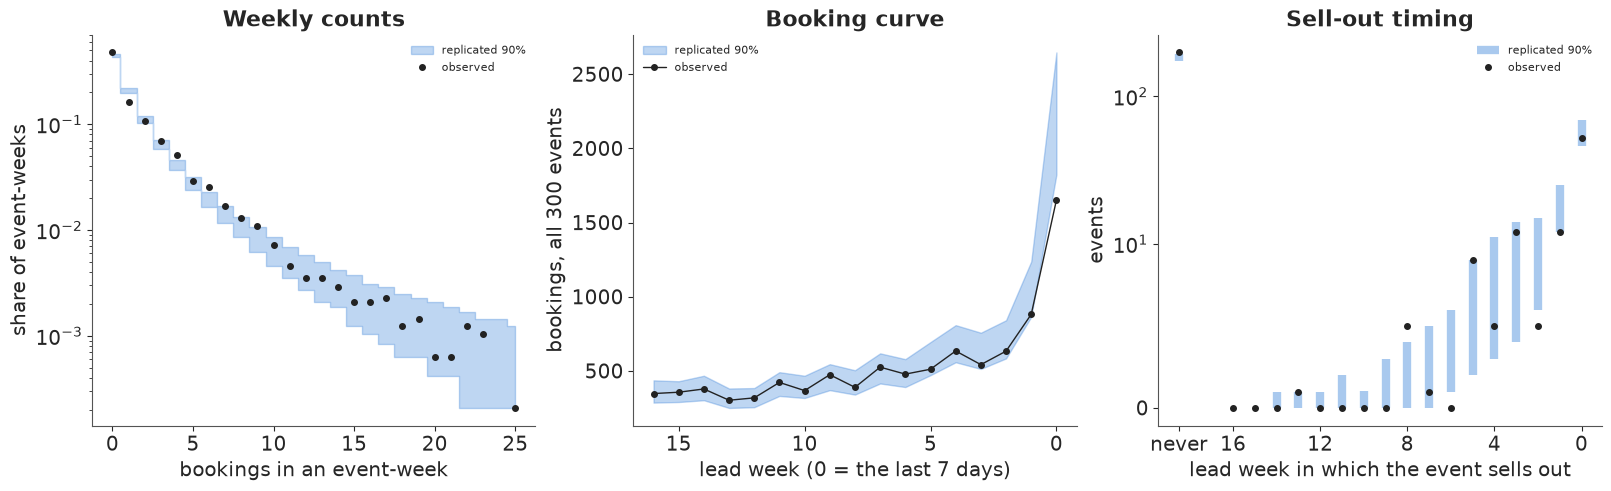

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
ax.fill_between(kk, np.percentile(rep_f, 5, 0), np.percentile(rep_f, 95, 0), color=BLUE, alpha=0.3, step="mid",
                label="replicated 90%")
ax.plot(kk, obs_f, "o", color=INK, ms=4, label="observed")
ax.set(yscale="log", xlabel="bookings in an event-week", ylabel="share of event-weeks", title="Weekly counts")
ax.legend(fontsize=8)
ax = axes[1]
ax.fill_between(np.arange(W)[::-1], np.percentile(tot_rep, 5, 0), np.percentile(tot_rep, 95, 0), color=BLUE,
                alpha=0.3, label="replicated 90%")
ax.plot(np.arange(W)[::-1], tot_obs, "o-", color=INK, ms=4, lw=1, label="observed")
ax.set(xlabel="lead week (0 = the last 7 days)", ylabel="bookings, all 300 events", title="Booking curve")
ax.invert_xaxis()
ax.legend(fontsize=8)
ax = axes[2]
bins_ = np.arange(-1, W + 1) - 0.5
xpos = np.r_[-2.5, np.arange(W)]                                     # "never" set apart on the left
h_rep = np.stack([np.histogram(s_, bins=bins_)[0] for s_ in SOW_rep])
lo_, hi_ = np.percentile(h_rep, 5, 0), np.percentile(h_rep, 95, 0)
ax.vlines(xpos, lo_, hi_, color=BLUE, lw=6, alpha=0.4, label="replicated 90%")
ax.plot(xpos, np.histogram(sow_obs, bins=bins_)[0], "o", color=INK, ms=4, label="observed")
ax.set_yscale("symlog", linthresh=10)
ax.set_xticks([-2.5, 0, 4, 8, 12, 16], ["never", "16", "12", "8", "4", "0"])
ax.set(xlabel="lead week in which the event sells out", ylabel="events", title="Sell-out timing")
ax.legend(fontsize=8);

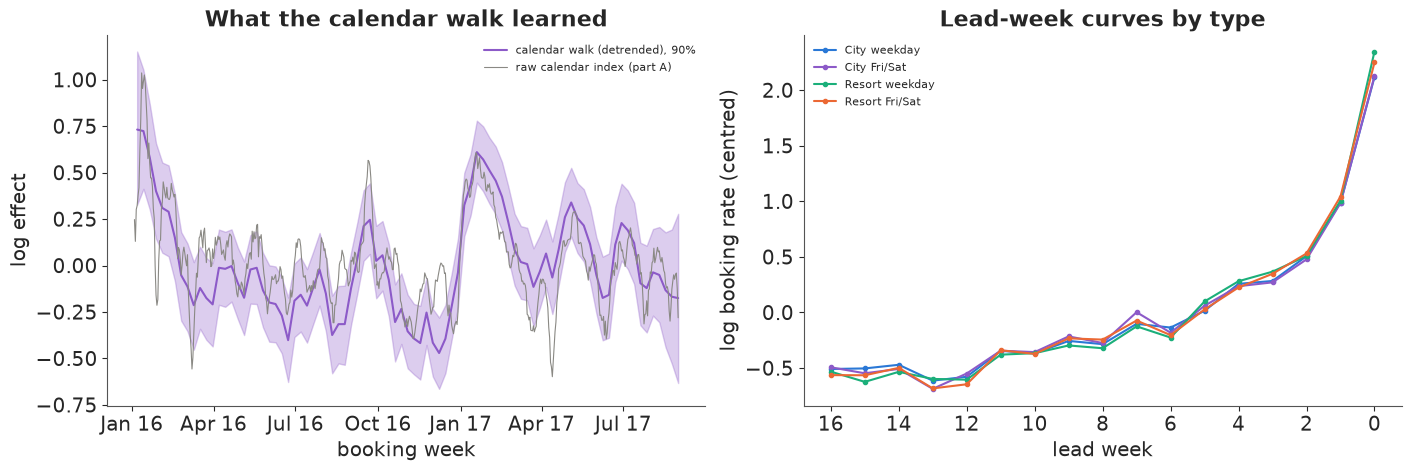

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
cb = idata.posterior["cal"].to_numpy().reshape(-1, n_cal)
wk_dates = BDATE_TS[0] + pd.to_timedelta((calw_all[EV].min() + np.arange(n_cal)) * 7 + 3, "D")
ax.fill_between(wk_dates, np.percentile(cb, 5, 0), np.percentile(cb, 95, 0), color=PURPLE, alpha=0.3)
ax.plot(wk_dates, cb.mean(0), color=PURPLE, lw=1.5, label="calendar walk (detrended), 90%")
ax.plot(BDATE_TS, S_CAL, color=MUTED, lw=0.8, label="raw calendar index (part A)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set(xlabel="booking week", ylabel="log effect", title="What the calendar walk learned")
ax.legend(fontsize=8)
ax = axes[1]
ct = (idata.posterior["curve"].to_numpy()[..., None, :] + idata.posterior["sd_tc"].to_numpy()[..., None, None]
      * idata.posterior["tc_z"].to_numpy()).reshape(-1, 4, W)
for t, nm in enumerate(TYPES):
    ax.plot(np.arange(W)[::-1], ct[:, t].mean(0), "o-", color=TCOL[nm], ms=3, label=nm)
ax.invert_xaxis()
ax.set(xlabel="lead week", ylabel="log booking rate (centred)", title="Lead-week curves by type")
ax.legend(fontsize=8);

Most weekly counts are reproduced (left panel of the first figure): 97% fall inside their 90%
predictive interval, more than 90% because discrete counts sit on the interval's edges. The shares
show a pattern, though: 48% of event-weeks have no booking against 43-46% replicated, 16% have
exactly one against 20-22%, and counts from 3 to 8 sit at or near the top of their bands: real
weeks are more often empty and, when not, busier than this negative binomial allows (a
zero-inflated or demand-state model might fit). The booking curve (middle panel) is matched until
the last week, where the observed 1,650 bookings fall below the band (1,820-2,650, median 2,200):
the model expects about a third more last-minute bookings than these events delivered.

The sell-out check (right panel, log scale) is the one a capacity model must pass. The model
predicts that 39% of the 300 events sell out (90% interval 35-43%) where 34% did, just outside the
interval: too pessimistic about capacity, as its surplus of last-week bookings suggests. The
timing has the right shape, most sell-outs in the last week and a thinning tail back to about
eight weeks out, with too many predicted one and two weeks out (the final week itself is matched)
and too few at about eight weeks out.

The calendar walk (left panel of the second figure) follows the raw index of part A through its
main swings after removing level and trend. Its band lies clear of zero at the start of 2016, in
the January 2017 peak and in a trough through November and December 2016 (about -0.65 to -0.2);
elsewhere it mostly includes zero. On weekly bins the four type curves (right panel) are close,
differing mostly in the last week, where resort weekday arrivals surge most.

## F · What can be repaired, and what cannot

Two of part C's habits survived every term we added to the t-minus model, for different reasons.

**Reactive pacing** is repairable. The rule sets spend from what has already been sold, a target
the planner wrote down and a random factor, so assignment depends only on observed history and
noise. What failed in part C was the estimator, not the data: fixed effects cannot handle feedback
from today's sales to tomorrow's spend, and the rule's inputs as controls moved the estimate
either way. The instrument of part C works (0.151). Simulating or weighting by the known rule
should also work, though we have not run them here: g-computation (Robins 1986) and
inverse-probability weighting (Robins, Hernán & Brumback 2000). Their price is precision, since
only the random part of spend is used, which is why a platform should **log its pacing rule and
its random part**, and make that part large on purpose: a sizeable random multiplier per event and
week, or events held out of the rule at random.

**Platform spend** is not repairable from these data. Booking-date effects absorb it entirely, and
weekly terms identify it only through an assumption about how smooth calendar demand is. The
calendar walk is the same assumption in another form: its prior on the weekly step says how fast
demand may move, and a brand campaign's effect would be borrowed from it; here the data pushed
that step to 0.19, so a tighter prior would likely hand a campaign part of the calendar (the
second exercise tests this). Only variation in the campaign unrelated to demand identifies it:
randomised on and off periods (switchbacks), or regions held out.

E103 showed how a few randomised measurements can calibrate many observational ones, and the idea
serves here: hold out ads from a random sample of events, compare their experimental lift with the
model's prediction, and learn the model's bias by type of event and spend to correct the rest.

## G · Where the next unit of spend goes

The marketing lead's question is not "what is $\beta$?" but "which events should get more money?".
We give each of the 300 events one more unit of budget - EUR 500 a day more (0.5 in the notebook's
units of EUR 1k), at its own flight pattern, stopping at sell-out as before - and ask how many
extra bookings it brings. The **truth** comes from replaying the decision world 40 times with the
same real organic bookings and fresh media noise, with and without the extra spend, on common
random numbers. The **naive** model, the hierarchical one of part D that keeps every week, answers
with its likelihood: the sum over weeks of $\mu_{ew}\,(e^{\beta A^1_{ew}} - e^{\beta A^0_{ew}})$,
with no capacity. The **better** model simulates: for each posterior draw, weekly
negative-binomial sales at the old and new spend, coupled through shared uniforms, cumulated and
capped at the event's rooms,

$$\Delta_e = E\Big[\min\big(\textstyle\sum_w Y_{ew}(A^1), C_e\big) - \min\big(\sum_w Y_{ew}(A^0), C_e\big)\Big].$$

One more choice matters. The better model's intercept contains the Mundlak term $\pi \log \bar
A_e$, which stands in for the event's unobserved size. Adding budget does not make an event
bigger, so we hold the intercept fixed when spend changes.

The comparison is in-sample and after the fact. Both models were fitted on these events' finished
sales, so their event effects, calendar walk and censored weeks already know how each sale went,
including whether it sold out; a planner deciding mid-sale knows less. And the truth replays each
event with its real organic bookings, so the "oracle" below knows each event's realised demand,
which the models average over.

In [20]:
DB = 0.5                                                    # one more unit: +EUR 0.5k a day, at the event's flights
SCALE1 = (SP_DEC["budget"] + DB) / SP_DEC["budget"]
A1w = adstock(SP_DEC["plan"] * SCALE1[:, None]).reshape(E, W, 7).mean(2)[EV]
t0 = time.time()
NS = 40
d_true, so_true = np.zeros(E), np.zeros(E)
for s in range(NS):                                          # same real organic bookings, fresh media noise
    D0 = simulate(SP_DEC, 50_000 + s, capped=True, stop=True)
    D1 = simulate(SP_DEC, 50_000 + s, capped=True, stop=True, scale=SCALE1)
    d_true += (D1["Ytot"] - D0["Ytot"]) / NS
    so_true += D0["sold"] / NS
dt, sot = d_true[EV], so_true[EV]
print(f"truth: {NS} paired simulations in {time.time() - t0:.0f} s; {dt.sum():.0f} extra bookings over {nE} events")
pn = az.extract(fits["naive: every week kept"], var_names=["beta", "mu0", "sd_a", "z", "curve"], num_samples=400,
                random_seed=2)
mu_n = np.exp((pn["mu0"].values + pn["sd_a"].values * pn["z"].values)[:, :, None] + pn["curve"].values.T[None])
bn = pn["beta"].values[None, :, None]
d_naive = (mu_n * (np.exp(bn * A1w[:, None, :]) - np.exp(bn * A0w[:, None, :]))).sum(2).mean(1)
d_better_d = np.zeros((nd, nE))
for d in range(nd):
    U = ru.uniform(size=(nE, W))
    d_better_d[d] = forward(*DRAW[d], A1w, U)[0] - forward(*DRAW[d], A0w, U)[0]
d_better = d_better_d.mean(0)
print(f"predicted extra bookings: naive {d_naive.sum():,.0f}, better {d_better.sum():,.0f} "
      f"(90%: {np.percentile(d_better_d.sum(1), 5):,.0f}-{np.percentile(d_better_d.sum(1), 95):,.0f}), truth {dt.sum():.0f}")
print(f"rank correlation with the truth: naive {stats.spearmanr(d_naive, dt)[0]:.2f}, "
      f"better {stats.spearmanr(d_better, dt)[0]:.2f}; naive with organic size {stats.spearmanr(d_naive, TOT0[EV])[0]:.2f}")
print(f"per event: truth {dt.min():.1f}-{dt.max():.1f}, better {d_better.min():.1f}-{d_better.max():.1f}, "
      f"naive {d_naive.min():.1f}-{d_naive.max():,.0f}")
pick = []
for K in (30, 60):
    for nm, sc_ in [("naive", d_naive), ("better", d_better), ("oracle", dt)]:
        top = np.argsort(-sc_)[:K]
        pick.append({"events funded": K, "chosen by": nm, "true extra bookings": dt[top].sum(),
                     "share that sell out anyway": sot[top].mean()})
    pick.append({"events funded": K, "chosen by": "random", "true extra bookings": dt.mean() * K,
                 "share that sell out anyway": sot.mean()})
print(pd.DataFrame(pick).round(2).to_string(index=False))
g_ = np.digitize(sot, [0.1, 0.9])
print("mean extra bookings per event, by how often the event sells out without the extra spend:")
print(pd.DataFrame({"events": np.bincount(g_, minlength=3), "truth": [dt[g_ == i].mean() for i in range(3)],
                    "naive": [d_naive[g_ == i].mean() for i in range(3)],
                    "better": [d_better[g_ == i].mean() for i in range(3)]},
                   index=["rarely (P < 10%)", "sometimes", "nearly always (P > 90%)"]).round(2).to_string())
print(f"better model's P(sell out) per event: mean {SO_rep.mean():.2f} against a true {sot.mean():.2f}, "
      f"correlation {np.corrcoef(SO_rep.mean(0), sot)[0, 1]:.2f}")

truth: 40 paired simulations in 3 s; 748 extra bookings over 300 events


predicted extra bookings: naive 6,607, better 689 (90%: 509-852), truth 748
rank correlation with the truth: naive -0.30, better 0.85; naive with organic size 0.94
per event: truth 0.0-8.5, better 0.0-6.1, naive 4.0-115
 events funded chosen by  true extra bookings  share that sell out anyway
            30     naive                 0.00                        1.00
            30    better               174.03                        0.03
            30    oracle               214.87                        0.00
            30    random                74.83                        0.35
            60     naive                15.10                        0.95
            60    better               335.40                        0.04
            60    oracle               373.28                        0.01
            60    random               149.66                        0.35
mean extra bookings per event, by how often the event sells out without the extra spend:
                         

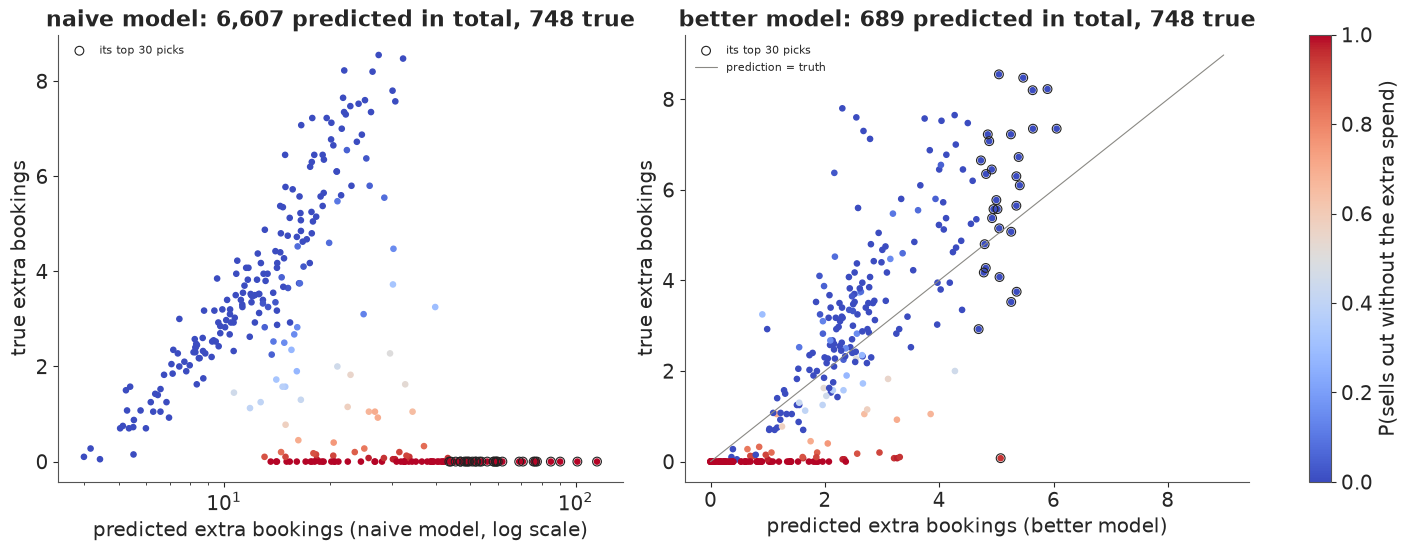

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, sc_, nm in [(axes[0], d_naive, "naive model"), (axes[1], d_better, "better model")]:
    s_ = ax.scatter(sc_, dt, c=sot, cmap="coolwarm", vmin=0, vmax=1, s=14)
    top = np.argsort(-sc_)[:30]
    ax.scatter(sc_[top], dt[top], facecolors="none", edgecolors=INK, s=40, lw=0.8, label="its top 30 picks")
    if nm == "naive model":                                          # its predictions span three orders
        ax.set_xscale("log")
    else:
        lim = max(sc_.max(), dt.max()) * 1.05
        ax.plot([0, lim], [0, lim], color=MUTED, lw=0.8, label="prediction = truth")
    ax.set(xlabel=f"predicted extra bookings ({nm}{', log scale' if nm == 'naive model' else ''})",
           ylabel="true extra bookings",
           title=f"{nm}: {sc_.sum():,.0f} predicted in total, {dt.sum():.0f} true")
    ax.legend(fontsize=8, loc="upper left")
fig.colorbar(s_, ax=axes, label="P(sells out without the extra spend)");

The naive model predicts about 6,600 extra bookings from the extra unit across the 300 events. The
truth is 748. The better model predicts about 690 (90% interval about 510-850), a little low,
which may come from its pessimism about sell-outs or from averaging over organic demand that the
truth holds fixed.

The totals are the smaller problem. The naive model's ranking of events is **negatively**
correlated with the truth (Spearman -0.30). Its predicted lift is proportional to an event's
expected sales, so it correlates 0.94 with the event's organic size and sends the money to the
biggest events - which are the ones that sell out anyway. All of its top 30 picks sell out without
the extra spend, and the true value of funding them is **zero** bookings. The better model's top
30 are worth about 175 bookings, against 215 for an oracle that knows realised demand and 75 for
30 chosen at random; at 60 events it captures about 335 of a possible 373, the naive model 15.

The left panel (log scale) shows how the naive model goes wrong. Among events that rarely sell out
(blue) its ranking is roughly right and its numbers three to four times too large, the inflated
$\beta$ of part D. The events that nearly always sell out (red, 89 of the 300) gain 0.02 bookings
each from more spend; the naive model gives them its largest predictions, 39 each. The better
model (right) puts them at the bottom, with about 1 each, and lines up the rest along the
diagonal. Its probability of selling out correlates 0.87 with the truth, with a mean of 0.39
against 0.35, though in-sample it has seen how each event's sale went.

### G1 · Daily lift is not incremental bookings

The daily model answers "how many more bookings today?"; the planner needs "how many more in
total?". They agree only if no one an ad brings would have booked later anyway. We simulate that
in three worlds with randomised budgets and weekly flights: half of every media booking ($\phi =
0.5$) is taken from the same event's later organic bookings, drawn without replacement. We fit the
daily model and compare its summed daily lift $\sum_{e,l} y_{el}\,(1 - e^{-\hat\beta A_{el}})$
with the true extra bookings, and refit each world without pull-forward.

In [22]:
t0 = time.time()
pf = []
for r in range(3):
    sp_g = spend_plan("budget", 30_000 + r, flight_sd=0.3)
    Dg = simulate(sp_g, 40_000 + r, phi=0.5)
    b = fit_poisson(Dg, np.ones(len(Dg["y"]), bool))
    b0_ = fit_poisson(simulate(sp_g, 40_000 + r), np.ones(len(Dg["y"]), bool))   # same world, no pull-forward
    net = Dg["Ytot"].sum() - TOT0.sum()
    pf.append({"world": r, "daily beta": b, "daily beta, no pull-forward": b0_,
               "media bookings (gross)": net + Dg["pulled"].sum(), "true extra bookings (net)": net,
               "summed daily lift": float((Dg["y"] * -np.expm1(-b * Dg["A"])).sum()),
               "... at the true beta": float((Dg["y"] * -np.expm1(-BETA * Dg["A"])).sum())})
pf = pd.DataFrame(pf)
pf["summed lift / net"] = pf["summed daily lift"] / pf["true extra bookings (net)"]
pf["... at the true beta / net"] = pf["... at the true beta"] / pf["true extra bookings (net)"]
print(f"pull-forward worlds (half of media buyers would have booked later), {time.time() - t0:.0f} s")
print(pf.round(3).to_string(index=False))

pull-forward worlds (half of media buyers would have booked later), 5 s
 world  daily beta  daily beta, no pull-forward  media bookings (gross)  true extra bookings (net)  summed daily lift  ... at the true beta  summed lift / net  ... at the true beta / net
     0       0.130                        0.144                  8805.0                     4863.0           7709.315              8693.192              1.585                       1.788
     1       0.111                        0.134                  8437.0                     4603.0           6609.588              8489.197              1.436                       1.844
     2       0.147                        0.160                  8467.0                     4743.0           8243.892              8363.970              1.738                       1.763


Media brings 8,400-8,800 bookings when they are made, but only 4,600-4,900 are extra. The daily
$\beta$ comes out low, 0.11-0.15 against 0.13-0.16 in the same worlds without pull-forward: the
borrowed bookings thin out the event's later days, which the model reads as baseline. Even so, its
summed lift of 6,600-8,200 overstates the true extra bookings by 44-74%. At the true $\beta$ it
would overstate them by 76-84%: the low daily estimate hides part of the overstatement, so a
correct daily model would mislead more, not less. Capacity does the same more bluntly: for a
sold-out event every booking an ad brings forward takes the last room from someone who would have
bought it later. Two designs can see the net: a comparison of **event totals** between events
given more and less budget at random - the experiment these worlds contain, and the first exercise
below - or a daily model with a depletion term after spend, which the same randomised flights
identify.

## H · Films and games

Box office and game launches have the same structure - a product with a date, sales on a clock
relative to it, media bought around it - and most of these traps carry over.

**Films.** The clock runs through the release: awareness builds before it and grosses decay after
it (Sawhney & Eliashberg 1996; Liu 2006 on word of mouth). Capacity is the number of screens, soft
and chosen: exhibitors allocate them from expected demand and adjust them from realised grosses
(Elberse & Eliashberg 2003). Marketing raises expected demand, which raises screens, which raise
gross, so screens are a **mediator**; since they also respond to a film's unobserved appeal,
controlling for them mixes appeal into the media coefficient. Spend follows expected gross, the
budget-follows-size trap at its strongest, so a pooled model of films needs the Mundlak term or
the budget tier in its film effects. Release dates are chosen too: Einav (2007) showed that
box-office seasonality reflects both demand and studios placing their strongest films in the best
weeks. Post-release spend reacts to the opening, and word of mouth makes an opening's surprise
persistent, the case in which feedback does most harm.

**Games.** A digital game has no capacity, so the sell-out traps disappear, though physical
editions, launch servers and pre-order caps can bring them back. Wishlists can be a mediator and a
pacing signal at once. Launch delays break t-minus alignment: spend planned against the announced
date lands at a different t-minus. After launch, discounts and new content are often timed with
marketing, so the store's sales calendar plays the booking date.

| | ticketed events (this notebook) | film releases | game launches |
|---|---|---|---|
| the clock | lead time to the event; booking date | weeks from release; calendar week | days to and from launch; calendar and store sales |
| capacity | seats or rooms, hard: a sell-out censors demand | screens, soft, set by exhibitors from expected and realised demand | none for digital; physical stock, servers |
| spend chosen by | expected size, pacing, the calendar | expected gross (budget tier), the opening weekend | budget tier, wishlist pacing |
| mediator, not a control | - | screens | wishlists, pre-orders |
| alignment trap | one pooled curve; spend on the calendar | release date chosen for the season (Einav 2007) | launch delays move t-minus under spend already made |

The fixes carry over in kind: model the sell-out (or the screens) as part of the outcome, not as a
control; put the size of the product into the hierarchy (Mundlak, budget tier); give the calendar
its own effects; and get some variation in spend that nobody chose with demand in mind.

In [23]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 231 s


## Summary

- **Stopping spend at sell-out doubled the estimated effect; dropping or censoring the sold-out
  days fixed it.** Fixed effects gave 0.316 against a true 0.15, and 0.148-0.150 without the
  sold-out days. The naive hierarchical model in PyMC, keeping every week, gave 0.403, mostly from
  the empty weeks after sell-outs. On weekly bins, censoring and dropping the sell-out week agreed
  within the noise (0.133 against 0.126, both on all 976 events).
- **Spend chosen with demand in mind biased the estimate both ways** (three worlds a habit, one
  strength): seasonal spend +81% without calendar terms (weekly terms left +7%), spend timed to
  each type's curve +23% with one pooled curve, reactive pacing -14%, with pace controls moving it
  anywhere from 0.121 to 0.189. An instrument from the pacing rule's random factor recovered
  0.151.
- **Random intercepts read event size as return on spend.** With budgets proportional to realised
  size, they gave 1.22 times the fixed-effects answer on daily data and 1.6 times in PyMC on
  weekly data (0.254 against 0.162 on the same 300 events); the Mundlak term brought them to
  0.164.
- **Brand spend that is the same for every event is not identified**: exactly aliased with
  booking-date effects, and resting on calendar smoothness with weekly terms (+11% when it
  followed the season).
- **A negative-binomial model with type curves, a detrended calendar walk, arrival-date trends,
  the Mundlak term and a censored sell-out week recovered the effect**: 0.16 (94% interval about
  0.11-0.20), clean diagnostics, a little over a minute. Its posterior sd was twice the censored
  Poisson models' (0.024 against 0.012-0.013), as part C's cluster-robust standard error warned.
  It over-predicts last-week bookings and sell-outs (39% against 34%).
- **The naive model would spend the next unit on events that sell out anyway.** It predicted about
  6,600 extra bookings where the truth was 748, ranked events against the truth (Spearman -0.30),
  and its top 30 were worth nothing; the better model predicted about 690 and its top 30 about
  175, against 215 for an oracle that knows realised demand. Both were scored in-sample, after the
  fact.
- **Daily lift is not incremental bookings.** With half of media buyers pulled forward, the daily
  $\beta$ came out low and the summed lift still overstated the true extra bookings by 44-74%. The
  notebook does not measure the net directly; the first exercise does.

## Try it yourself

1. **Measure pull-forward with the budget experiment.** In the pull-forward worlds budgets were
   randomised across events. Fit a PyMC model of event **totals** on log budget, with hotel x
   month x weekday effects and a negative-binomial likelihood, and turn it into extra bookings per
   extra unit. Does it recover the net 4,600-4,900 rather than the summed daily lift, and how many
   events does it need before its interval excludes the daily answer?
2. **A switchback for the brand campaign.** Make the platform series follow the season, then
   switch it off on a random third of booking dates. Fit the better model with its calendar walk
   and a platform term. Is $\beta$ now identified, and how much does its posterior move when the
   walk's prior sd goes from 0.05 to 0.3?
3. **Spend a fixed budget.** Give the marketing lead 150 extra units for the 300 events, at most
   three per event. Allocate them greedily by each model's posterior expected extra bookings,
   recomputing with capacity after every unit, and score the two allocations against the replayed
   truth. How much of the better model's shortfall against the oracle comes from its slight
   pessimism about sell-outs?